# 🚗 DriveGuard AI — Exploratory Data Analysis

> **Domain:** Intelligent Transportation / Smart-City Traffic Enforcement
> **Problem:** Two-stage computer-vision system — (1) detect & classify vehicles on CCTV frames, (2) detect & read Indian number plates
> **Datasets:**
> - **UA-DETRAC** — fixed-camera traffic video frames, YOLO-format labels (`images/{train,val}` + `labels/{train,val}`)
> - **Indian Number Plates (DataCluster Labs)** — mobile-phone photographs of Indian plates, Pascal-VOC XML with plate text
> **Industry context:** Automated e-challan systems, ITMS / smart-city command centres, toll plazas, parking and gate automation, fleet analytics

---

### 🧭 How every step in this notebook is structured

| Block | Position | Purpose |
|---|---|---|
| **❓ Why** | above the code | Why this analysis / plot was chosen |
| **💼 Business Insight** | above the code | What the business risk or opportunity is |
| **Code + Plot** | middle | Reproducible analysis, plots rendered inline only |
| **📌 Observation** | below the code | What the plot shows, specifically |
| **💡 Pipeline / Engineering Decision** | below the code | The concrete decision this finding drives in the training / serving pipeline |

> 📝 **Execution note:** all plots are rendered inline only — nothing is written to disk by this notebook (no `plots/` folder, no `savefig`).

---

### 🗺️ Roadmap

| Part | Steps | Focus |
|---|---|---|
| **A — Setup** | 1–2 | Config, imports, dataset discovery |
| **B — UA-DETRAC** | 3–18 | Inventory → integrity → class balance → geometry → scale → sequence leakage → quality → crowding → anchors |
| **C — Indian Number Plates** | 19–26 | Inventory → annotation parsing → integrity → EXIF/geometry → plate shape → plate text → crop quality → visual audit |
| **D — Synthesis** | 27–28 | Cross-dataset domain gap → risk register & pipeline configuration |

# 🅐 Part A — Setup & Dataset Discovery

## 🔹 Step 1 — Imports, Global Config & Plot Style

### ❓ Why
A reproducible EDA starts with a single configuration cell: one place for paths, random seeds, sampling budgets and plot style. Every later cell reads from this config, so the notebook behaves identically on any machine and any re-run.

### 💼 Business Insight
In a capstone that will be reviewed by hiring managers and later handed to an MLOps team, reproducibility is a deliverable. A pinned seed and a single `DATA_ROOT` mean results can be audited, re-run, and trusted — a baseline expectation in production ML teams.

In [1]:
import os, re, json, math, random, warnings
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import yaml
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from scipy.spatial.distance import jensenshannon
from sklearn.cluster import KMeans
from IPython.display import display

warnings.filterwarnings("ignore")
%matplotlib inline

# ── Reproducibility ──────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ── Paths (override with env var DRIVEGUARD_DATA_ROOT if needed) ─────────
DATA_ROOT  = Path(os.environ.get("DRIVEGUARD_DATA_ROOT", r"D:\Data_Science_Capstone_Datasets\driveguard-ai"))
DETRAC_DIR = DATA_ROOT / "content" / "UA-DETRAC" / "DETRAC_Upload"
PLATES_DIR = DATA_ROOT / "Indian_Number_Plates"

IMG_EXT          = {".jpg", ".jpeg", ".png", ".bmp"}
SPLITS           = ["train", "val"]
SAMPLE_N         = 600     # images per split used for pixel-level statistics (quality, resolution)
PLATE_SAMPLE_MAX = 500     # cap for pixel-level plate analysis (full dataset can be 20k+ HD images)

# ── Plot style (inline only — nothing is saved to disk) ──────────────────
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12.5,
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180)

# ── Shared containers & helpers ──────────────────────────────────────────
FINDINGS = {}          # numeric evidence collected step-by-step, consumed by the final summary

def list_files(folder, exts=None):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(p for p in folder.rglob("*") if p.is_file() and (exts is None or p.suffix.lower() in exts))

def sample_paths(paths, n, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(paths), size=min(n, len(paths)), replace=False)
    return [paths[i] for i in sorted(idx)]

def read_bgr(path, flags=cv2.IMREAD_COLOR):
    # np.fromfile + imdecode is safe for Windows paths containing spaces / unicode / brackets
    buf = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(buf, flags)

def read_rgb(path):
    img = read_bgr(path)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print(f"DATA_ROOT  : {DATA_ROOT}")
print(f"DETRAC_DIR : {DETRAC_DIR}")
print(f"PLATES_DIR : {PLATES_DIR}")
print(f"Seed={SEED} | SAMPLE_N={SAMPLE_N} | PLATE_SAMPLE_MAX={PLATE_SAMPLE_MAX}")

DATA_ROOT  : D:\Data_Science_Capstone_Datasets\driveguard-ai
DETRAC_DIR : D:\Data_Science_Capstone_Datasets\driveguard-ai\content\UA-DETRAC\DETRAC_Upload
PLATES_DIR : D:\Data_Science_Capstone_Datasets\driveguard-ai\Indian_Number_Plates
Seed=42 | SAMPLE_N=600 | PLATE_SAMPLE_MAX=500


### 📌 Observation
- The notebook resolved `DATA_ROOT` to `D:\Data_Science_Capstone_Datasets\driveguard-ai`, with UA-DETRAC under `content\UA-DETRAC\DETRAC_Upload` and the plates under `Indian_Number_Plates`; seed 42 and the sampling budgets (600 images per split, 500 plate images) are printed for the record.
- The 600-frame DETRAC budget is a small slice of the data (600 of 83,791 train frames = 0.72 %, 600 of 56,340 val frames = 1.07 %), but the frames are spread over 60 train and 40 val sequences, i.e. roughly 10 and 15 frames per sequence.
- The plate cap of 500 never binds, because the whole plate collection is only 47 images.

### 💡 Pipeline / Engineering Decision
- **Sampling is adequate for distribution shape, not for rare events:** because neighbouring frames are almost identical (lag-1 autocorrelation 0.98, Step 13), a random sample spread over all 100 sequences describes brightness, sharpness and resolution well. Rare conditions (night frames are about 1.4 % of the sample) are *not* reliably measured by 600 frames, so any night-specific claim must be re-measured on the full set.
- **Seeded `sample_paths` stays,** so every figure in this notebook is reproducible on re-run.
- **`PLATE_SAMPLE_MAX` is irrelevant at this scale** and is kept only so the same code survives a larger plate dataset.
- **`FINDINGS` stays the single evidence registry:** the final config in Step 28 is generated from it, not typed by hand.

## 🔹 Step 2 — Dataset Discovery & Folder-Structure Validation

### ❓ Why
Before analysing anything, verify that the on-disk structure matches the expected contract (YOLO `images/` + `labels/` per split; plate images + XML annotations). A bar chart of file counts and disk footprint per component gives an immediate sanity check, and failing fast here saves hours of debugging a half-loaded dataset later.

### 💼 Business Insight
Data-pipeline failures caused by missing or mis-placed folders are among the most common causes of silent training bugs (training on an empty split, or on images without labels). Validating the contract up-front is the cheapest form of data quality control, and it mirrors the *schema check* step of any production ingestion job.

Pascal-VOC XML files discovered for plates : 47


,component,exists,n_files,size_mb,extensions
0,UA-DETRAC / images / train,True,83791,5608.4,.jpg
1,UA-DETRAC / images / val,True,56340,4234.0,.jpg
2,UA-DETRAC / labels / train,True,82085,22.4,.txt
3,UA-DETRAC / labels / val,True,56167,25.3,.txt
4,Plates / detection images,True,27,86.3,.jpg
5,Plates / detection annotations,True,27,0.0,.xml
6,Plates / OCR images,True,21,69.3,".ini, .jpg"
7,Plates / OCR annotations,True,20,0.0,.xml


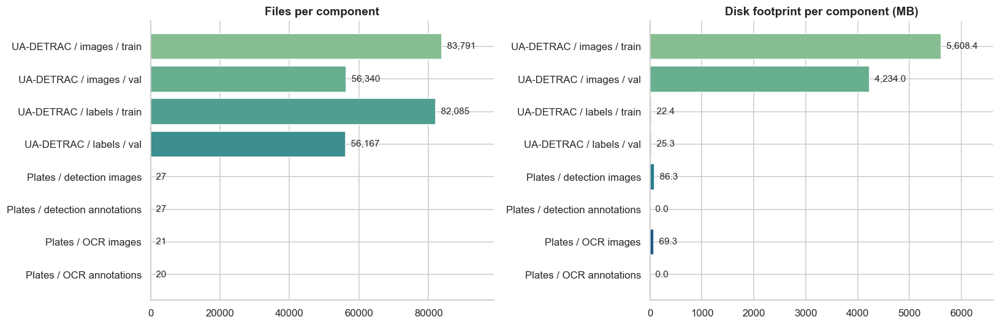

In [2]:
PLATE_IMG_DIRS  = [PLATES_DIR / "Sample_Images", DATA_ROOT / "number_plate_images_ocr"]
PLATE_ANN_DIRS  = [DATA_ROOT / "Annotations",    DATA_ROOT / "number_plate_annos_ocr"]
PLATE_SET_NAMES = ["detection_set (boxes only)", "ocr_set (boxes + text)"]

components = {
    "UA-DETRAC / images / train":     DETRAC_DIR / "images" / "train",
    "UA-DETRAC / images / val":       DETRAC_DIR / "images" / "val",
    "UA-DETRAC / labels / train":     DETRAC_DIR / "labels" / "train",
    "UA-DETRAC / labels / val":       DETRAC_DIR / "labels" / "val",
    "Plates / detection images":      PLATE_IMG_DIRS[0],
    "Plates / detection annotations": PLATE_ANN_DIRS[0],
    "Plates / OCR images":            PLATE_IMG_DIRS[1],
    "Plates / OCR annotations":       PLATE_ANN_DIRS[1],
}

rows = []
for name, path in components.items():
    files = list_files(path)
    rows.append({
        "component":  name,
        "exists":     path.exists(),
        "n_files":    len(files),
        "size_mb":    round(sum(f.stat().st_size for f in files) / 1e6, 1),
        "extensions": ", ".join(sorted({f.suffix.lower() for f in files})) or "-",
    })
structure_df = pd.DataFrame(rows)

PLATE_XMLS = [p for d in PLATE_ANN_DIRS for p in list_files(d, {".xml"})]
print(f"Pascal-VOC XML files discovered for plates : {len(PLATE_XMLS)}")
display(structure_df)

missing = structure_df.loc[~structure_df["exists"], "component"].tolist()
if missing:
    raise FileNotFoundError(f"Missing folders: {missing}. Check DATA_ROOT = {DATA_ROOT}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = sns.color_palette("crest", len(structure_df))
for ax, col, title, fmt in [(axes[0], "n_files", "Files per component", "{:,.0f}"),
                            (axes[1], "size_mb", "Disk footprint per component (MB)", "{:,.1f}")]:
    ax.barh(structure_df["component"], structure_df[col], color=colors)
    ax.invert_yaxis(); ax.set_title(title)
    for y, v in enumerate(structure_df[col]):
        ax.text(v, y, "  " + fmt.format(v), va="center", fontsize=10)
    ax.set_xlim(0, structure_df[col].max() * 1.18)
plt.tight_layout(); plt.show()

FINDINGS["xml_files_found"] = len(PLATE_XMLS)

### 📌 Observation
- All eight expected components exist. UA-DETRAC: 83,791 train images (5,608 MB) and 56,340 val images (4,234 MB), against 82,085 and 56,167 label files (22.4 MB and 25.3 MB). Plates: 27 detection images (86.3 MB) with 27 XML files, and 21 files in the OCR image folder (20 `.jpg` plus one `.ini`) with 20 XML files.
- The two bar charts show a gap of about three orders of magnitude: roughly 140,000 DETRAC frames against 47 plate photos, and about 9.8 GB against about 0.16 GB on disk.
- Per-image weight differs enormously: a DETRAC frame is about 67-75 KB, a plate photo about 3.2-3.5 MB.
- The extra `.ini` file in the OCR image folder is a Windows `desktop.ini` artefact, not an image.
- The plate data lives in **four different folders** (two image folders, two annotation folders), not in the single `Indian_Number_Plates` folder.

### 💡 Pipeline / Engineering Decision
- **Explicit path lists replace discovery heuristics:** `PLATE_IMG_DIRS` and `PLATE_ANN_DIRS` name the four plate folders. Guessing folder names was exactly what produced the earlier "0 XML files" failure.
- **Extension filtering is mandatory in every loader** (`IMG_EXT`, `.xml`, `.txt`), so `desktop.ini` and similar files can never be read as data.
- **Two independent data modules:** one YOLO-format loader for DETRAC and one VOC-XML loader for plates, each with its own config; they are never merged into a single dataset.
- **The fail-fast folder contract passed** and stays as the first task of the ingestion job.

# 🅑 Part B — UA-DETRAC (Vehicle Detection)

## 🔹 Step 3 — UA-DETRAC Inventory — Image ↔ Label Pairing & Split Ratio

### ❓ Why
A detector is only as good as its image–label pairing. Grouped bars of images vs label files per split expose orphan images (no label file) and orphan labels (no image) instantly, and a split-share pie confirms the train/validation ratio.

### 💼 Business Insight
Orphan files silently corrupt training: an image without a label file may be treated as pure background and teach the detector to ignore real vehicles, which at deployment appears as missed detections and lost violation evidence. A split ratio far from the usual 80/20 or 90/10 would also make validation metrics unreliable.

,images,label_files,images_without_label,labels_without_image,share_%
split,,,,,
train,83791,82085,1706,0,59.79
val,56340,56167,173,0,40.21


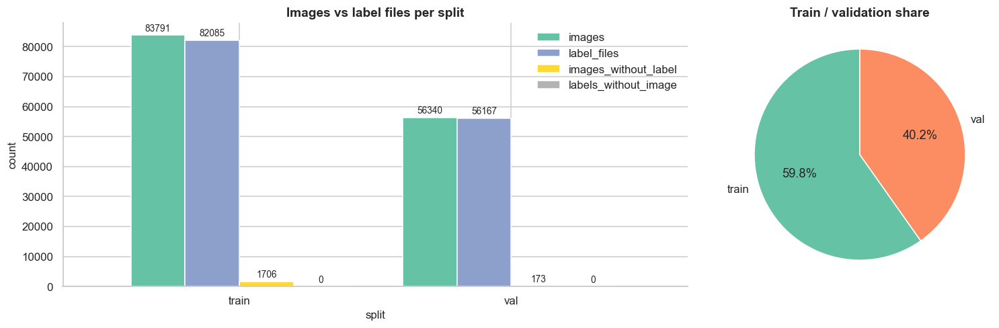

Train images: 83,791 | Val images: 56,340 | Orphan files: 1879


In [3]:
DETRAC_IMAGES, DETRAC_LABELS, rows = {}, {}, []
for sp in SPLITS:
    DETRAC_IMAGES[sp] = list_files(DETRAC_DIR / "images" / sp, IMG_EXT)
    DETRAC_LABELS[sp] = list_files(DETRAC_DIR / "labels" / sp, {".txt"})
    img_stems = {p.stem for p in DETRAC_IMAGES[sp]}
    lbl_stems = {p.stem for p in DETRAC_LABELS[sp]}
    rows.append({
        "split": sp,
        "images": len(img_stems),
        "label_files": len(lbl_stems),
        "images_without_label": len(img_stems - lbl_stems),
        "labels_without_image": len(lbl_stems - img_stems),
    })

inventory_df = pd.DataFrame(rows).set_index("split")
inventory_df["share_%"] = (inventory_df["images"] / inventory_df["images"].sum() * 100).round(2)
display(inventory_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 1]})
plot_cols = ["images", "label_files", "images_without_label", "labels_without_image"]
inventory_df[plot_cols].plot(kind="bar", ax=axes[0], rot=0, width=0.8, colormap="Set2")
axes[0].set_title("Images vs label files per split"); axes[0].set_ylabel("count")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%d", padding=2, fontsize=9)
axes[1].pie(inventory_df["images"], labels=inventory_df.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("Set2"), wedgeprops={"edgecolor": "white"})
axes[1].set_title("Train / validation share")
plt.tight_layout(); plt.show()

FINDINGS["n_train_images"] = int(inventory_df.loc["train", "images"])
FINDINGS["n_val_images"]   = int(inventory_df.loc["val", "images"])
FINDINGS["orphans"] = int(inventory_df[["images_without_label", "labels_without_image"]].sum().sum())
print(f"Train images: {FINDINGS['n_train_images']:,} | Val images: {FINDINGS['n_val_images']:,} | Orphan files: {FINDINGS['orphans']}")

### 📌 Observation
- Train has 83,791 images but only 82,085 label files, so **1,706 train images (2.04 %) have no label file**; val has 56,340 images and 56,167 label files, so **173 val images (0.31 %)** have none. There are **zero orphan label files**, so the problem only goes in one direction (1,879 images in total).
- The split is 59.8 % train and 40.2 % val by images, which is far from a usual 80/20 or 90/10 ratio.
- The sequence counts in Step 13 (60 train, 40 val) follow the standard UA-DETRAC benchmark layout, so the `val` folder is most likely the benchmark's test videos, not a random hold-out.

### 💡 Pipeline / Engineering Decision
- **The 1,879 unlabeled images are quarantined until inspected.** Missing label files are most likely frames with no annotated vehicle (some exporters simply skip them), but that has not been verified. Action: view about 50 random frames from this set; if they are empty road, keep them as background negatives (the usual YOLO behaviour), otherwise exclude them from training and from validation metrics.
- **The provided 60/40 split is kept as-is:** it is the official, video-disjoint partition (confirmed leakage-free in Step 13), and re-shuffling frames would destroy that property.
- **Pairing remains by file stem,** and the validator reports `images_without_label` as a tracked KPI on every run.

## 🔹 Step 4 — Parsing YOLO Labels into a Tidy DataFrame

### ❓ Why
Raw `.txt` labels cannot be analysed at scale. Parsing every file into one row per bounding box (`split, image_id, class, xc, yc, w, h`) gives a tidy table on which every later statistic is a one-line group-by. Class names are read from the dataset's own `data.yaml` when present.

### 💼 Business Insight
Per-box analytics are the foundation for every model-design decision: loss weighting, anchor sizes, input resolution and augmentation. Doing it on 100 % of the labels (not a sample) means no class or scene type is under-represented in our conclusions.

⚠️  data.yaml not found — using FALLBACK UA-DETRAC class map (verify against your dataset): {0: 'car', 1: 'bus', 2: 'van', 3: 'others'}

Parsed 1,274,055 boxes from 138,252 label files | malformed lines: 0


,split,image_id,cls,xc,yc,w,h,cls_name
0,train,MVI_20011_img00001,1,0.700807,0.851667,0.166719,0.300370,bus
1,train,MVI_20011_img00001,1,0.605469,0.263907,0.049167,0.079741,bus
2,train,MVI_20011_img00001,1,0.586276,0.191315,0.036719,0.055704,bus
3,train,MVI_20011_img00001,1,0.544115,0.149005,0.029167,0.048009,bus
4,train,MVI_20011_img00001,1,0.591432,0.148042,0.030781,0.036472,bus


split        object
image_id     object
cls           int64
xc          float64
yc          float64
w           float64
h           float64
cls_name     object
Memory: 300.9 MB


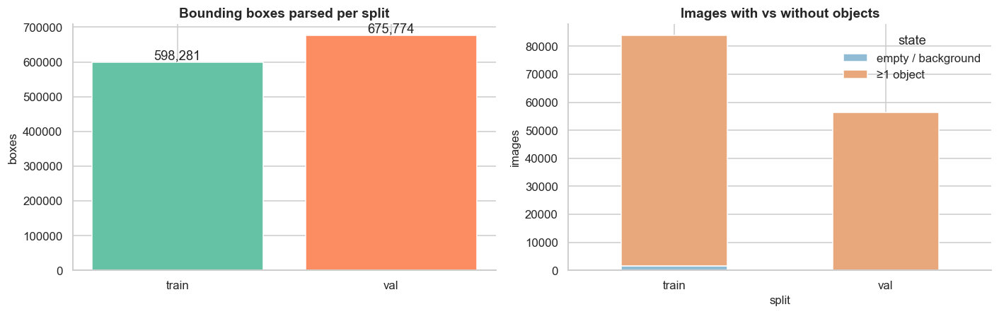

In [4]:
def find_class_names():
    candidates = [DETRAC_DIR / "data.yaml", DETRAC_DIR.parent / "data.yaml", DETRAC_DIR / "dataset.yaml"]
    candidates += list(DETRAC_DIR.glob("*.yaml")) + list(DETRAC_DIR.parent.glob("*.yaml"))
    for c in candidates:
        if c.exists():
            try:
                with open(c, "r") as f:
                    names = (yaml.safe_load(f) or {}).get("names")
            except Exception:
                continue
            if isinstance(names, list):
                return {i: n for i, n in enumerate(names)}, str(c)
            if isinstance(names, dict):
                return {int(k): v for k, v in names.items()}, str(c)
    return None, None

CLASS_NAMES, yaml_src = find_class_names()
if CLASS_NAMES is None:
    CLASS_NAMES = {0: "car", 1: "bus", 2: "van", 3: "others"}
    print("⚠️  data.yaml not found — using FALLBACK UA-DETRAC class map (verify against your dataset):", CLASS_NAMES)
else:
    print(f"Class map loaded from {yaml_src}: {CLASS_NAMES}")

records, per_image, malformed = [], [], 0
for sp in SPLITS:
    for lp in DETRAC_LABELS[sp]:
        n = 0
        with open(lp, "r") as f:
            for line in f:
                parts = line.split()
                if not parts:
                    continue
                if len(parts) < 5:
                    malformed += 1; continue
                try:
                    c = int(float(parts[0])); xc, yc, w, h = map(float, parts[1:5])
                except ValueError:
                    malformed += 1; continue
                records.append((sp, lp.stem, c, xc, yc, w, h)); n += 1
        per_image.append((sp, lp.stem, n))

det = pd.DataFrame(records, columns=["split", "image_id", "cls", "xc", "yc", "w", "h"])
det["cls_name"] = det["cls"].map(lambda c: CLASS_NAMES.get(c, f"class_{c}"))

# image-level table (every image on disk, including images with zero objects)
img_df = pd.DataFrame([(sp, p.stem, str(p)) for sp in SPLITS for p in DETRAC_IMAGES[sp]],
                      columns=["split", "image_id", "path"])
obj_counts = pd.DataFrame(per_image, columns=["split", "image_id", "n_objects"])
img_df = img_df.merge(obj_counts, how="left", on=["split", "image_id"])
img_df["has_label_file"] = img_df["n_objects"].notna()
img_df["n_objects"] = img_df["n_objects"].fillna(0).astype(int)
img_df["sequence"] = img_df["image_id"].str.extract(r"(MVI_\d+)", flags=re.I)[0]
img_df["frame"]    = img_df["image_id"].str.extract(r"img0*(\d+)", flags=re.I)[0].astype(float)

# consistent colours per class for every later plot
all_classes  = sorted(det["cls_name"].unique())
CLASS_PALETTE = dict(zip(all_classes, sns.color_palette("Set2", len(all_classes))))

print(f"\nParsed {len(det):,} boxes from {img_df['has_label_file'].sum():,} label files | malformed lines: {malformed}")
display(det.head())
print(det.dtypes.to_string())
print(f"Memory: {det.memory_usage(deep=True).sum()/1e6:.1f} MB")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
box_per_split = det["split"].value_counts().reindex(SPLITS)
axes[0].bar(box_per_split.index, box_per_split.values, color=sns.color_palette("Set2", 2))
for i, v in enumerate(box_per_split.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Bounding boxes parsed per split"); axes[0].set_ylabel("boxes")
state = img_df.assign(state=np.where(img_df["n_objects"] > 0, "≥1 object", "empty / background")) \
              .groupby(["split", "state"]).size().unstack(fill_value=0).reindex(SPLITS)
state.plot(kind="bar", stacked=True, ax=axes[1], rot=0, color=["#8fbcd4", "#e8a87c"][:state.shape[1]] if state.shape[1] <= 2 else None)
axes[1].set_title("Images with vs without objects"); axes[1].set_ylabel("images")
plt.tight_layout(); plt.show()

FINDINGS["n_boxes"] = int(len(det)); FINDINGS["malformed_lines"] = int(malformed)
FINDINGS["empty_image_pct"] = round(float((img_df["n_objects"] == 0).mean() * 100), 2)

### 📌 Observation
- **1,274,055 boxes were parsed from 138,252 label files with 0 malformed lines.** Coordinates are normalised 0-1, i.e. standard YOLO format, and file names such as `MVI_20011_img00001` confirm that sequence id and frame number can be recovered from the name.
- The warning at the top shows that **`data.yaml` was not found**, so the fallback class map is in use. Class names in this notebook come from the **fallback map** (`0=car, 1=bus, 2=van, 3=others`) because no `data.yaml` was found. The data contradicts that map (see Step 14), so every class below is quoted by **class id**, with the displayed (unreliable) name in brackets.
- The box counts differ sharply from the image counts: train has 598,281 boxes and val has 675,774, **even though val has about 33 % fewer images**. The right-hand chart shows that only a thin slice of train (about 2 %) and almost none of val are empty or unlabeled frames.
- The full table uses only about 301 MB of memory, so every statistic in Part B is computed on 100 % of the boxes.

### 💡 Pipeline / Engineering Decision
- **The class map must be corrected before any training run.** Class id 1 holds 82.6 % of boxes and Step 14 shows it sitting on ordinary passenger cars, so it is almost certainly the car class and not "bus". Confirm the real mapping from the dataset's own documentation (or by cropping about 20 boxes per class id) and set `CLASS_NAMES` accordingly; all numbers in this notebook are valid by class id, only the names are wrong.
- **`det` is the single source of truth** for box-level analytics; no later step re-reads label files.
- **`has_label_file` is kept as a column** in `img_df`, so images without a label file stay distinguishable from images with an empty label file.
- **Sequence and frame ids from the file names** drive the leakage audit and the frame sub-sampling policy (Step 13).

## 🔹 Step 5 — Label Integrity Audit (Coordinates, Duplicates, Degenerate Boxes)

### ❓ Why
Seven independent checks on every box — malformed lines, unknown class ids, out-of-range coordinates, zero-size boxes, boxes crossing the image border, exact duplicates and tiny boxes. A horizontal bar of each issue as a percentage of all boxes turns an abstract validation into a visible defect budget.

### 💼 Business Insight
Label noise puts a hard ceiling on achievable mAP: duplicates inflate the loss for the same vehicle, degenerate boxes produce NaN gradients, and out-of-range coordinates crash augmentation pipelines mid-training. Finding them at EDA time costs minutes; finding them after a failed 12-hour GPU run costs money and schedule.

,check,n_boxes,severity,pct_of_boxes
0,Malformed label lines,0,Critical,0.0
1,Unknown class ids,0,Critical,0.0
2,"Coordinates outside [0, 1]",0,Critical,0.0
3,Zero / negative width or height,0,Critical,0.0
4,Boxes crossing image border (>0.5 %),0,Warning,0.0
5,Exact duplicate boxes within an image,0,Warning,0.0
6,Tiny boxes (area < 0.01 % of image),0,Warning,0.0


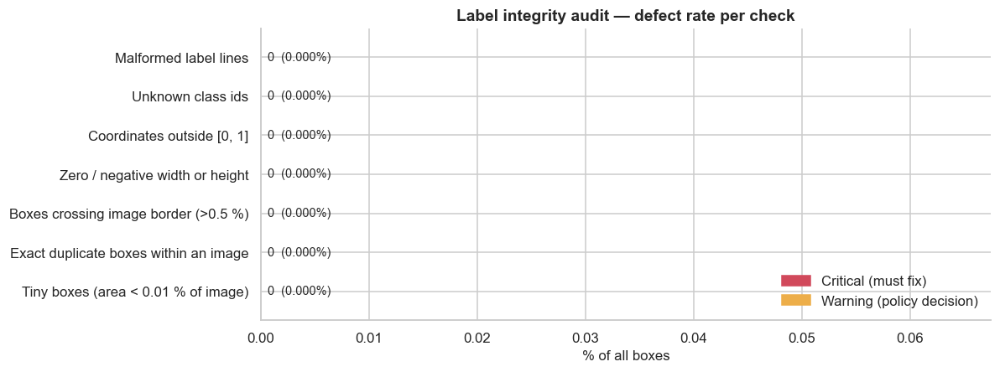

Critical defects: 0 | Warnings: 0


In [5]:
x1, x2 = det["xc"] - det["w"] / 2, det["xc"] + det["w"] / 2
y1, y2 = det["yc"] - det["h"] / 2, det["yc"] + det["h"] / 2
coords = det[["xc", "yc", "w", "h"]]

checks = pd.DataFrame([
    ("Malformed label lines",                        malformed,                                                           "Critical"),
    ("Unknown class ids",                            int((~det["cls"].isin(CLASS_NAMES.keys())).sum()),                   "Critical"),
    ("Coordinates outside [0, 1]",                   int(((coords < 0) | (coords > 1)).any(axis=1).sum()),                "Critical"),
    ("Zero / negative width or height",              int(((det["w"] <= 0) | (det["h"] <= 0)).sum()),                      "Critical"),
    ("Boxes crossing image border (>0.5 %)",         int(((x1 < -0.005) | (y1 < -0.005) | (x2 > 1.005) | (y2 > 1.005)).sum()), "Warning"),
    ("Exact duplicate boxes within an image",        int(det.duplicated(subset=["split", "image_id", "cls", "xc", "yc", "w", "h"]).sum()), "Warning"),
    ("Tiny boxes (area < 0.01 % of image)",          int(((det["w"] * det["h"]) < 1e-4).sum()),                           "Warning"),
], columns=["check", "n_boxes", "severity"])
checks["pct_of_boxes"] = (checks["n_boxes"] / len(det) * 100).round(4)
display(checks)

fig, ax = plt.subplots(figsize=(11, 4.2))
bar_colors = checks["severity"].map({"Critical": "#d1495b", "Warning": "#edae49"})
ax.barh(checks["check"], checks["pct_of_boxes"], color=bar_colors)
ax.invert_yaxis(); ax.set_xlabel("% of all boxes"); ax.set_title("Label integrity audit — defect rate per check")
xmax = max(checks["pct_of_boxes"].max(), 0.05)
ax.set_xlim(0, xmax * 1.35)
for y, (n, p) in enumerate(zip(checks["n_boxes"], checks["pct_of_boxes"])):
    ax.text(p, y, f"  {n:,}  ({p:.3f}%)", va="center", fontsize=9.5)
ax.legend(handles=[mpatches.Patch(color="#d1495b", label="Critical (must fix)"),
                   mpatches.Patch(color="#edae49", label="Warning (policy decision)")], loc="lower right")
plt.tight_layout(); plt.show()

FINDINGS["integrity_critical"] = int(checks.loc[checks["severity"] == "Critical", "n_boxes"].sum())
FINDINGS["integrity_warning"]  = int(checks.loc[checks["severity"] == "Warning", "n_boxes"].sum())
FINDINGS["duplicate_boxes"]    = int(checks.loc[checks["check"].str.startswith("Exact duplicate"), "n_boxes"].iloc[0])
FINDINGS["tiny_boxes"]         = int(checks.loc[checks["check"].str.startswith("Tiny"), "n_boxes"].iloc[0])
print(f"Critical defects: {FINDINGS['integrity_critical']:,} | Warnings: {FINDINGS['integrity_warning']:,}")

### 📌 Observation
- **All seven checks return 0 across 1,274,055 boxes:** no malformed lines, no unknown class ids, no coordinates outside [0, 1], no zero or negative sizes, no boxes crossing the border by more than 0.5 %, no exact duplicates and no boxes below 0.01 % of the image area. Every bar in the chart is empty, and the summary reads 0 critical defects and 0 warnings.
- A result of zero tiny boxes means the smallest annotated box covers at least 0.01 % of a 960×540 frame (about 52 px², roughly 7×7 px), and zero border-crossing boxes suggests the converter already clipped boxes to the frame.
- Format-level cleanliness is not the same as completeness: Step 14 shows visible vehicles that carry no box at all.

### 💡 Pipeline / Engineering Decision
- **No cleaning filters are needed right now** (no clipping, no de-duplication, no dropping). The validators stay in the pipeline anyway as regression tests, because a future data drop could break any of these rules silently.
- **Add a near-duplicate rule:** Step 17 finds a few box pairs with IoU around 0.9-0.95, which an *exact*-duplicate check cannot catch.
- **Completeness is handled elsewhere:** unlabeled-but-visible vehicles are an annotation-coverage problem, addressed through the ignore-region decision in Step 14, not through these validators.

## 🔹 Step 6 — Class Distribution — Linear vs Log Scale

### ❓ Why
A bar chart of box counts per class is the first view of class balance. Pairing a linear panel with a log-scale panel is deliberate: the linear view shows how dominant the majority class is, while the log view makes the minority classes readable at all.

### 💼 Business Insight
Traffic analytics and enforcement depend on minority vehicle types — buses and vans (commercial vehicles) carry different tolls, route restrictions and violation rules than cars. If the model is only accurate on the dominant class, the system will look excellent on aggregate accuracy and fail on exactly the vehicle categories the business cares about most.

,boxes,share_%,inv_freq_weight
cls_name,,,
bus,1052408,82.60,0.055
others,105436,8.28,0.547
van,95570,7.50,0.604
car,20641,1.62,2.795


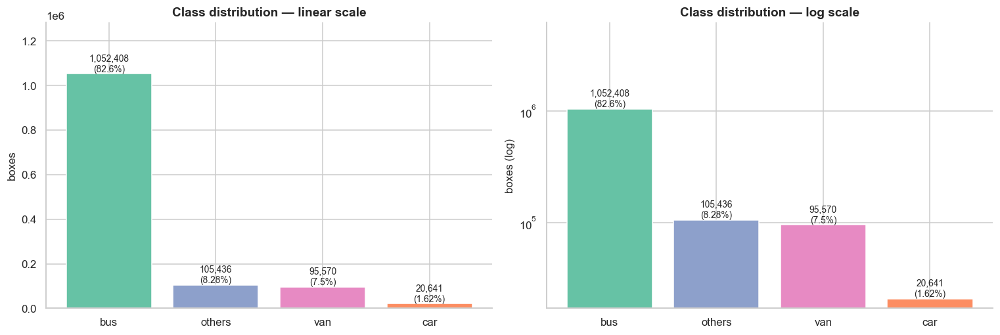

Majority class: bus (82.6%) | Imbalance ratio (max/min): 51.0x


In [6]:
cls_counts = det["cls_name"].value_counts()
cls_pct = (cls_counts / cls_counts.sum() * 100).round(2)
imbalance_ratio = cls_counts.max() / cls_counts.min()

# inverse-frequency class weights (normalised to mean = 1)
inv = 1.0 / cls_counts
class_weights = (inv / inv.mean()).round(3)

class_table = pd.DataFrame({"boxes": cls_counts, "share_%": cls_pct, "inv_freq_weight": class_weights})
display(class_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, log in zip(axes, [False, True]):
    ax.bar(cls_counts.index, cls_counts.values, color=[CLASS_PALETTE[c] for c in cls_counts.index])
    if log: ax.set_yscale("log")
    ax.set_title("Class distribution — " + ("log scale" if log else "linear scale"))
    ax.set_ylabel("boxes" + (" (log)" if log else ""))
    for i, (n, p) in enumerate(zip(cls_counts.values, cls_pct.values)):
        ax.text(i, n, f"{n:,}\n({p}%)", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(top=cls_counts.max() * (6 if log else 1.22))
plt.tight_layout(); plt.show()

FINDINGS["class_counts"] = cls_counts.to_dict()
FINDINGS["majority_class"] = cls_counts.idxmax(); FINDINGS["majority_pct"] = float(cls_pct.max())
FINDINGS["imbalance_ratio"] = round(float(imbalance_ratio), 1)
FINDINGS["class_weights"] = class_weights.to_dict()
print(f"Majority class: {FINDINGS['majority_class']} ({FINDINGS['majority_pct']}%) | Imbalance ratio (max/min): {imbalance_ratio:,.1f}x")

### 📌 Observation
- Class names in this notebook come from the **fallback map** (`0=car, 1=bus, 2=van, 3=others`) because no `data.yaml` was found. The data contradicts that map (see Step 14), so every class below is quoted by **class id**, with the displayed (unreliable) name in brackets.
- **Class id 1 (shown as "bus") has 1,052,408 boxes (82.60 %)**, class id 3 ("others") 105,436 (8.28 %), class id 2 ("van") 95,570 (7.50 %) and **class id 0 ("car") only 20,641 (1.62 %)**. The imbalance ratio is **51.0×** (max/min).
- On the linear panel one bar towers over the rest; on the log panel class ids 3 and 2 sit within about 10 % of each other near 10⁵ boxes, while class id 0 is a further 5× lower and 50× below the majority.
- The inverse-frequency weights range from 0.055 (class id 1) to 2.795 (class id 0), a ratio of about 51×. A traffic dataset in which one class holds 82.6 % of the boxes is the normal pattern for passenger cars.

### 💡 Pipeline / Engineering Decision
- **Evaluation is per class id, never aggregate-only:** a high mAP dominated by the 82.6 % class will not be accepted if the rarest classes (ids 0, 2, 3) have poor recall.
- **Use softened weights, not raw ones:** raw inverse frequency spans 51×, which destabilises training. A square-root version compresses it to about 7× (√51 ≈ 7.1). Combine it with repeat-factor sampling of images that contain class id 0 (only 1.62 % of boxes).
- **No majority down-sampling:** deleting class-1 boxes would throw away hard negatives and scene variety.
- **Weights are keyed by class id** and are regenerated once the corrected class map is applied, so names can never drift between training and serving.

## 🔹 Step 7 — Train vs Validation Class Distribution (Distribution-Shift Check)

### ❓ Why
Validation metrics are only meaningful if the validation set has the same class mix as training. A side-by-side proportion chart plus a Jensen–Shannon distance (0 = identical, 1 = completely different) tests this directly, and a delta chart in percentage points shows exactly which class drifted.

### 💼 Business Insight
If validation over- or under-represents a class, reported mAP will not reflect real-world performance, and a model could be promoted to production on misleading numbers. Verifying split representativeness protects every downstream go/no-go decision.

split,train,val,delta_pp (val − train)
cls_name,,,
bus,84.217,81.174,-3.042
car,0.623,2.503,1.880
others,5.625,10.623,4.998
van,9.536,5.700,-3.836


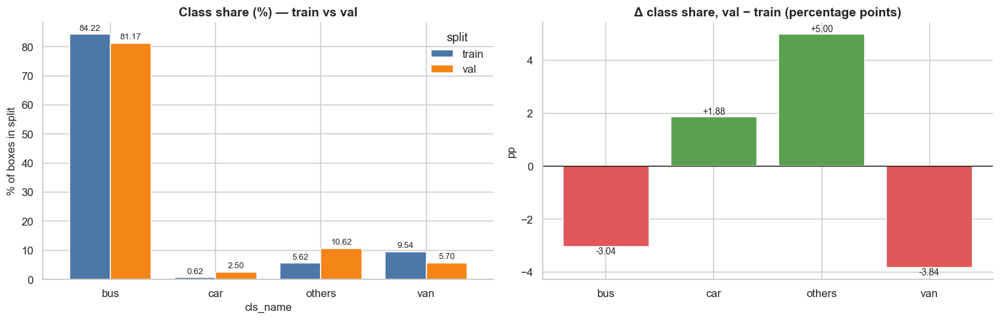

Jensen–Shannon distance (train vs val): 0.1172  |  max |Δ| = 4.998 pp  |  mean objects/image: {'train': 7.14, 'val': 11.99}


In [7]:
prop = pd.crosstab(det["cls_name"], det["split"]).reindex(columns=SPLITS, fill_value=0)
prop_pct = prop / prop.sum() * 100
prop_pct["delta_pp (val − train)"] = prop_pct["val"] - prop_pct["train"]
js_distance = float(jensenshannon(prop["train"] / prop["train"].sum(), prop["val"] / prop["val"].sum(), base=2))
display(prop_pct.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
prop_pct[SPLITS].plot(kind="bar", ax=axes[0], rot=0, width=0.78, color=["#4c78a8", "#f58518"])
axes[0].set_title("Class share (%) — train vs val"); axes[0].set_ylabel("% of boxes in split")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", padding=2, fontsize=8.5)
delta = prop_pct["delta_pp (val − train)"]
axes[1].bar(delta.index, delta.values, color=np.where(delta >= 0, "#59a14f", "#e15759"))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Δ class share, val − train (percentage points)"); axes[1].set_ylabel("pp")
for i, v in enumerate(delta.values):
    axes[1].text(i, v, f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
plt.tight_layout(); plt.show()

mean_obj = img_df.groupby("split")["n_objects"].mean().round(2).to_dict()
FINDINGS["js_distance"] = round(js_distance, 4)
FINDINGS["max_abs_delta_pp"] = round(float(delta.abs().max()), 3)
print(f"Jensen–Shannon distance (train vs val): {js_distance:.4f}  |  max |Δ| = {delta.abs().max():.3f} pp  |  mean objects/image: {mean_obj}")

### 📌 Observation
- **The validation split does not have the same class mix as training.** Class id 1 falls from 84.22 % to 81.17 % (-3.04 pp), id 2 from 9.54 % to 5.70 % (-3.84 pp), while **id 3 almost doubles, 5.62 % to 10.62 % (+5.00 pp)** and id 0 rises 4× in relative terms, 0.62 % to 2.50 % (+1.88 pp).
- The Jensen-Shannon distance is **0.1172** and the largest class swing is **4.998 pp**; the delta chart shows two bars up and two down, with the largest bar belonging to class id 3.
- Scene density differs too: **7.14 objects per image in train against 11.99 in val**.
- In absolute terms, about 82 % of all class-id-0 boxes (roughly 16,900 of 20,641) and about 68 % of all class-id-3 boxes sit in **val**, so the rarest classes are mostly *not* in the training data.

### 💡 Pipeline / Engineering Decision
- **The alert rule fires** (JS 0.1172 > 0.05, and two classes exceed 2 pp), so this split is a distribution-shifted benchmark, not a random hold-out. This is the expected result of a video-disjoint split: different cameras and scenes carry different vehicle mixes.
- **Keep the official split for the headline number, but never use val alone for model selection.** Run 5-fold `GroupKFold` over all 100 sequences to get a variance estimate, and report the benchmark val score next to the cross-validated score.
- **Rare classes need protecting in training:** class id 0 has only about 3,700 train boxes. Sequences containing ids 0 and 3 should be oversampled, and the final model is retrained on train + val after model selection so those classes are seen in full.
- **Per-class and per-sequence reporting is mandatory,** because an aggregate score on this val set would hide the shift.

## 🔹 Step 8 — Objects per Image — Scene Density (Histogram, Box Plot, ECDF)

### ❓ Why
Three complementary views of scene density: a histogram for shape, a box plot for split comparison, and an ECDF (empirical cumulative distribution) to read exact percentiles. The 99th and 99.9th percentiles are what determine detector capacity settings.

### 💼 Business Insight
Traffic density varies from empty off-peak roads to rush-hour congestion — the exact moments a traffic-management system is most valuable. A detector tuned on average scenes silently drops vehicles in dense scenes, which means under-counting at peak hours and missed violations when volume is highest.

,count,mean,std,min,50%,90%,99%,99.9%,max
split,,,,,,,,,
train,83791.0,7.14,4.87,0.0,6.0,14.0,22.0,24.0,27.0
val,56340.0,11.99,7.77,0.0,10.0,23.0,35.0,40.0,41.0


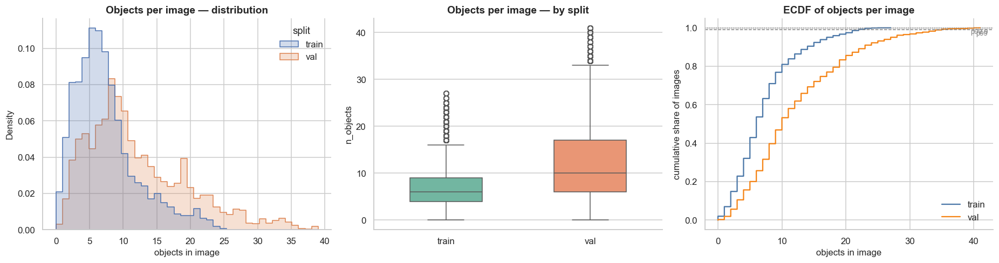

mean=9.09 | p99=32 | p99.9=39 | max=41 → recommended max_det = 100


In [8]:
density_stats = img_df.groupby("split")["n_objects"].describe(percentiles=[.5, .9, .99, .999]).round(2)
display(density_stats)

p99, p999 = img_df["n_objects"].quantile([.99, .999])
clip = int(p999)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(data=img_df[img_df["n_objects"] <= clip], x="n_objects", hue="split", stat="density",
             common_norm=False, bins=40, element="step", ax=axes[0])
axes[0].set_title("Objects per image — distribution"); axes[0].set_xlabel("objects in image")
sns.boxplot(data=img_df, x="split", y="n_objects", ax=axes[1], palette="Set2", width=0.5)
axes[1].set_title("Objects per image — by split"); axes[1].set_xlabel("")
for sp, col in zip(SPLITS, ["#4c78a8", "#f58518"]):
    v = np.sort(img_df.loc[img_df["split"] == sp, "n_objects"].values)
    axes[2].step(v, np.arange(1, len(v) + 1) / len(v), where="post", label=sp, color=col)
for q, ls in [(0.99, "--"), (0.999, ":")]:
    axes[2].axhline(q, color="grey", ls=ls, lw=1)
    axes[2].text(axes[2].get_xlim()[1] * 0.98, q - 0.03, f"p{q*100:g}", ha="right", fontsize=8.5, color="grey")
axes[2].set_title("ECDF of objects per image"); axes[2].set_xlabel("objects in image"); axes[2].set_ylabel("cumulative share of images")
axes[2].legend()
plt.tight_layout(); plt.show()

max_det = int(max(100, np.ceil(p999 * 1.5 / 50) * 50))
FINDINGS.update({"objs_mean": round(float(img_df["n_objects"].mean()), 2), "objs_p99": float(p99),
                 "objs_p999": float(p999), "objs_max": int(img_df["n_objects"].max()), "max_det": max_det})
print(f"mean={FINDINGS['objs_mean']} | p99={p99:.0f} | p99.9={p999:.0f} | max={FINDINGS['objs_max']} → recommended max_det = {max_det}")

### 📌 Observation
- **Val scenes are much busier than train scenes.** Train: mean 7.14, median 6, p90 14, p99 22, max 27 objects per image. Val: mean 11.99, median 10, p90 23, p99 35, p99.9 40, max 41. Combined: mean 9.09, p99 32, p99.9 39.
- In the histogram, train peaks sharply at 5-6 objects and ends near 27, while val is flatter, peaks around 8 and has a long tail to about 40 with a bump near 20.
- In the box plots, val's median (10) sits just above train's 75th percentile (9), and train's outliers stop at 27 where val's reach 41.
- On the ECDF, the val curve is shifted 4-10 objects to the right of train; val's p90 (23) is already close to train's p99.9 (24).

### 💡 Pipeline / Engineering Decision
- **`max_det = 100`** (rule: p99.9 × 1.5 rounded up, minimum 100): more than twice the maximum observed count of 41, so predictions are never truncated.
- **Train never shows more than 27 objects, val reaches 41:** Mosaic augmentation stays on, since stitching four frames raises the average from about 7 to about 28 objects per image, which covers val's p90-p99 range.
- **Density-aware sampling and evaluation:** oversample train frames in the top density decile (14 or more objects), and report a "crowded" evaluation slice defined as 23 or more objects (val's p90).
- **Counting KPIs use a density-binned error,** because MAE averaged over all frames would hide failures in the crowded tail.

## 🔹 Step 9 — Image Resolution & File-Size Audit

### ❓ Why
Detection accuracy and compute cost are both set by input resolution. A sampled resolution audit (reading only image headers — cheap) confirms whether all frames share one resolution; a file-size histogram checks for compression inconsistencies. The modal resolution becomes the reference frame for converting normalised boxes to real pixels.

### 💼 Business Insight
Mixed resolutions break batching assumptions and make per-pixel metrics meaningless. File size is also a proxy for storage and streaming cost: at 25 FPS per camera across hundreds of cameras, per-frame size drives bandwidth and archive budgets in a real deployment.

split,train,val
resolution,,
960×540,600,600


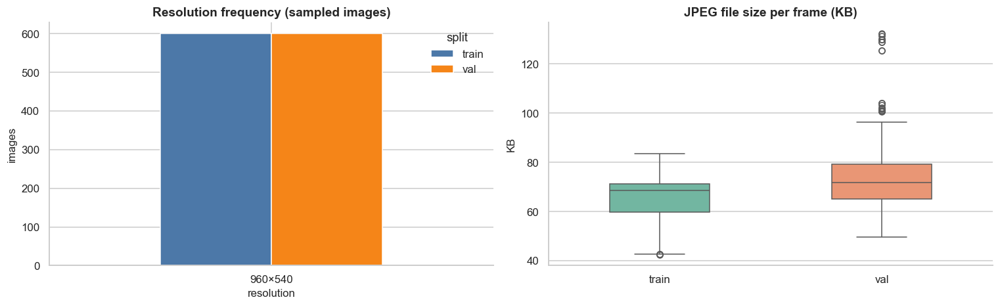

Modal resolution = 960×540 | single resolution across sample: True | median file size: 69.4 KB


In [9]:
DETRAC_SAMPLE = {sp: sample_paths(DETRAC_IMAGES[sp], SAMPLE_N) for sp in SPLITS}

res_rows = []
for sp in SPLITS:
    for p in DETRAC_SAMPLE[sp]:
        with Image.open(p) as im:
            w, h = im.size
        res_rows.append((sp, p.name, w, h, p.stat().st_size / 1024))
res_df = pd.DataFrame(res_rows, columns=["split", "file", "w", "h", "size_kb"])
res_df["resolution"] = res_df["w"].astype(str) + "×" + res_df["h"].astype(str)
res_df["megapixels"] = res_df["w"] * res_df["h"] / 1e6

res_counts = res_df.groupby(["resolution", "split"]).size().unstack(fill_value=0)
display(res_counts)
IMG_W, IMG_H = map(int, res_df.groupby(["w", "h"]).size().idxmax())
uniform = res_df["resolution"].nunique() == 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
res_counts.reindex(columns=SPLITS, fill_value=0).plot(kind="bar", ax=axes[0], rot=0, color=["#4c78a8", "#f58518"])
axes[0].set_title("Resolution frequency (sampled images)"); axes[0].set_ylabel("images")
sns.boxplot(data=res_df, x="split", y="size_kb", ax=axes[1], palette="Set2", width=0.45)
axes[1].set_title("JPEG file size per frame (KB)"); axes[1].set_xlabel(""); axes[1].set_ylabel("KB")
plt.tight_layout(); plt.show()

FINDINGS.update({"img_w": IMG_W, "img_h": IMG_H, "resolution_uniform": bool(uniform),
                 "median_file_kb": round(float(res_df["size_kb"].median()), 1)})
print(f"Modal resolution = {IMG_W}×{IMG_H} | single resolution across sample: {uniform} | median file size: {FINDINGS['median_file_kb']} KB")

### 📌 Observation
- **Every sampled frame in both splits is exactly 960×540** (600 of 600 in each), so there is a single resolution and no per-image resize logic is needed.
- The median file size is 69.4 KB. The box plots show val frames are slightly larger than train frames (median about 72 KB against about 68 KB) with a tail of outliers up to about 132 KB, while train's maximum is about 84 KB.
- The larger val files are consistent with val's higher contrast and sharpness in Step 15, i.e. more detail per frame.

### 💡 Pipeline / Engineering Decision
- **960×540 is the pixel reference for every scale statistic** from Step 10 onward.
- **The loader needs no resize logic beyond one letterbox:** a single known source resolution makes the transform to the training size deterministic (and the serving path simple).
- **JPEG-compression augmentation (quality about 60-95)** is added, because val frames are noticeably "heavier" than train frames and compression differences are a realistic deployment shift.
- **The resolution check stays in the ingestion validator,** so a camera at a different resolution triggers a warning instead of silently feeding off-distribution frames.

## 🔹 Step 10 — Bounding-Box Size & Shape Analysis (Pixels, Area, Aspect Ratio)

### ❓ Why
Normalised YOLO coordinates hide the real object scale. Converting to pixels and examining width–height density, log-area distributions per class and aspect-ratio spread tells us what the detector actually has to see. Log-area is used because box area spans several orders of magnitude.

### 💼 Business Insight
Vehicle size on the image is a direct proxy for distance from the camera. Small boxes correspond to far-away vehicles, which are exactly the ones lost first when input resolution is cut to save compute — and lost vehicles mean lost counts, lost classifications and lost evidence.

,boxes,w_px_median,h_px_median,sqrt_area_p5,sqrt_area_median,sqrt_area_p95,aspect_median
cls_name,,,,,,,
bus,1052408,74.6,45.7,26.4,58.1,147.7,1.5
car,20641,145.9,105.3,48.1,115.5,202.0,1.4
others,105436,173.8,102.3,61.9,132.6,296.2,1.6
van,95570,80.4,60.3,29.3,68.9,178.9,1.4


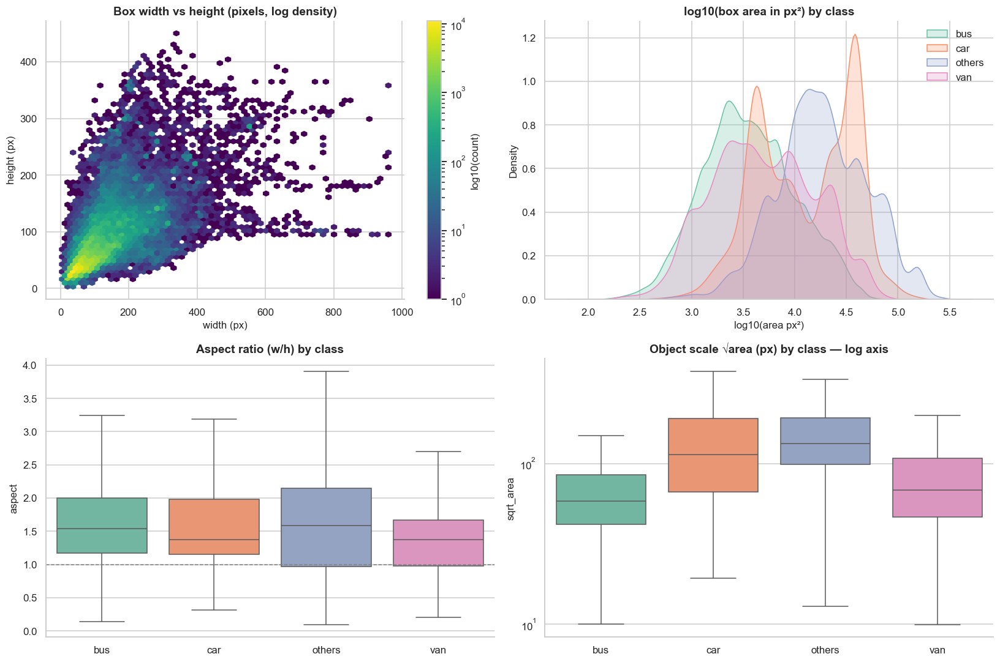

Object scale (√area): p5=27.1 px | median=62.9 px | p95=174.1 px


In [10]:
det["w_px"] = det["w"] * IMG_W
det["h_px"] = det["h"] * IMG_H
det["area_px"] = det["w_px"] * det["h_px"]
det["sqrt_area"] = np.sqrt(det["area_px"])
det["aspect"] = det["w_px"] / det["h_px"].replace(0, np.nan)

summary = det.groupby("cls_name").agg(
    boxes=("cls", "size"),
    w_px_median=("w_px", "median"), h_px_median=("h_px", "median"),
    sqrt_area_p5=("sqrt_area", lambda s: s.quantile(.05)),
    sqrt_area_median=("sqrt_area", "median"),
    sqrt_area_p95=("sqrt_area", lambda s: s.quantile(.95)),
    aspect_median=("aspect", "median"),
).round(1)
display(summary)

det_s = det.sample(min(len(det), 200_000), random_state=SEED)   # plotting sample for heavy KDE / hexbin

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
hb = axes[0, 0].hexbin(det_s["w_px"], det_s["h_px"], gridsize=60, bins="log", cmap="viridis", mincnt=1)
axes[0, 0].set_title("Box width vs height (pixels, log density)"); axes[0, 0].set_xlabel("width (px)"); axes[0, 0].set_ylabel("height (px)")
plt.colorbar(hb, ax=axes[0, 0], label="log10(count)")

for c in all_classes:
    s = det_s.loc[det_s["cls_name"] == c, "area_px"]
    if s.nunique() > 2:
        sns.kdeplot(np.log10(s.clip(lower=1)), ax=axes[0, 1], label=c, fill=True, alpha=.25, color=CLASS_PALETTE[c],
                    common_norm=False, warn_singular=False)
axes[0, 1].set_title("log10(box area in px²) by class"); axes[0, 1].set_xlabel("log10(area px²)"); axes[0, 1].legend()

sns.boxplot(data=det_s, x="cls_name", y="aspect", ax=axes[1, 0], palette=CLASS_PALETTE, showfliers=False, order=all_classes)
axes[1, 0].axhline(1, color="grey", ls="--", lw=1)
axes[1, 0].set_title("Aspect ratio (w/h) by class"); axes[1, 0].set_xlabel("")

sns.boxplot(data=det_s, x="cls_name", y="sqrt_area", ax=axes[1, 1], palette=CLASS_PALETTE, showfliers=False, order=all_classes)
axes[1, 1].set_yscale("log"); axes[1, 1].set_title("Object scale √area (px) by class — log axis"); axes[1, 1].set_xlabel("")
plt.tight_layout(); plt.show()

FINDINGS["median_sqrt_area_px"] = round(float(det["sqrt_area"].median()), 1)
FINDINGS["sqrt_area_p5_px"] = round(float(det["sqrt_area"].quantile(.05)), 1)
FINDINGS["sqrt_area_p95_px"] = round(float(det["sqrt_area"].quantile(.95)), 1)
print(f"Object scale (√area): p5={FINDINGS['sqrt_area_p5_px']} px | median={FINDINGS['median_sqrt_area_px']} px | p95={FINDINGS['sqrt_area_p95_px']} px")

### 📌 Observation
- **Object scale (√area) is wide:** p5 = 27.1 px, median = 62.9 px, p95 = 174.1 px, a 6.4× spread between p5 and p95. The width-height hexbin has its densest region at roughly 50-100 px wide and 25-60 px high and spreads diagonally to about 400×450 px. Two horizontal streaks appear at heights of about 100 px and 180 px, running out to 600-950 px wide.
- **The two classes with the largest boxes are the two rarest** (excluding the majority): class id 3 ("others") has median √area 132.6 px (173.8×102.3 px) and class id 0 ("car") 115.5 px (145.9×105.3 px), while class id 1 ("bus") is only 58.1 px (74.6×45.7 px) and class id 2 ("van") 68.9 px.
- The log-area KDEs show class ids 1 and 2 overlapping heavily around 2,000-4,000 px², class id 0 as two sharp peaks (about 4,000 px² and 40,000 px²) and class id 3 with a broad peak and a tail to about 160,000 px².
- Aspect ratio is similar for every class: medians 1.4-1.6, interquartile range roughly 1.0-2.1, with class id 3 reaching about 3.9.

### 💡 Pipeline / Engineering Decision
- **Multi-scale training is mandatory:** boxes range from about 10 px to about 450 px, so scale jitter of roughly ±50 % (0.5-1.5×) is enabled and the detector keeps stride-8 features.
- **Size, not just frequency, separates the classes:** the rare classes are the large, near-camera vehicles, so they provide few but easy-to-see examples, while the dominant class holds the small distant vehicles. This supports class-weighted loss over simply collecting more of the majority class.
- **Review the extreme-width boxes:** inspect the widest 0.1 % of boxes (the 600-950 px streaks) to check whether they are real long vehicles or merged annotations, before deciding whether to filter them.
- **Aspect ratios of 1.4-1.6 are within normal prior ranges,** so no special box parameterisation is needed.

## 🔹 Step 11 — Small-Object Analysis & Input-Resolution Trade-off

### ❓ Why
COCO-style size buckets (small < 32², medium 32²–96², large > 96² pixels) show which classes are small-object problems. A second curve then answers a concrete engineering question: *what fraction of boxes shrinks below 8 px (the smallest feature-map stride) at each candidate input size?* That curve turns resolution selection into a quantified trade-off.

### 💼 Business Insight
Input resolution is the main lever between accuracy and cost. Doubling the input roughly quadruples GPU compute per frame; across hundreds of camera streams that is a direct hardware and cloud bill. Choosing the smallest resolution that still preserves small vehicles is the cheapest accuracy win available.

size_bucket,small (<32²),medium (32²–96²),large (>96²)
cls_name,,,
bus,10.97,70.19,18.84
car,0.66,41.75,57.59
others,0.41,22.41,77.19
van,8.70,60.28,31.02
ALL CLASSES,9.76,65.03,25.21


,imgsz,share_below_8px_%,relative_compute
0,640,0.02,1.00
1,800,0.00,1.56
2,960,0.00,2.25
3,1280,0.00,4.00


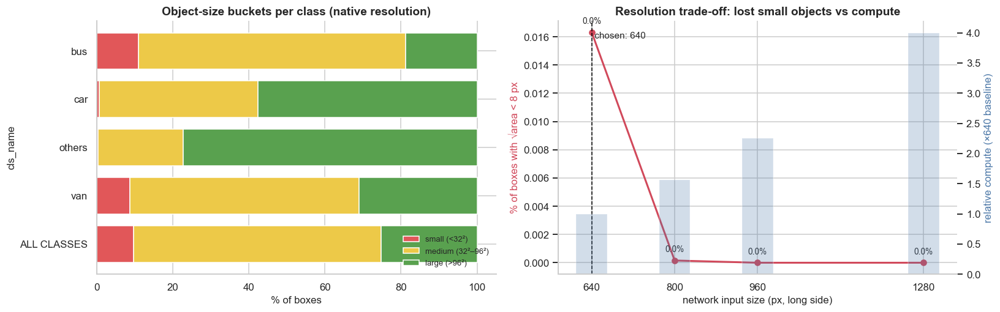

Small objects at native resolution: 9.76% | recommended input size: 640


In [11]:
SMALL, MEDIUM = 32 ** 2, 96 ** 2
det["size_bucket"] = pd.cut(det["area_px"], [0, SMALL, MEDIUM, np.inf],
                            labels=["small (<32²)", "medium (32²–96²)", "large (>96²)"], right=False)
det["is_small"] = det["area_px"] < SMALL

bucket_pct = pd.crosstab(det["cls_name"], det["size_bucket"], normalize="index") * 100
bucket_pct.loc["ALL CLASSES"] = det["size_bucket"].value_counts(normalize=True).reindex(bucket_pct.columns) * 100
display(bucket_pct.round(2))

CANDIDATES = [640, 800, 960, 1280]
shares = []
for s in CANDIDATES:
    scale = s / max(IMG_W, IMG_H)
    shares.append(float((det["sqrt_area"] * scale < 8).mean() * 100))
res_tradeoff = pd.DataFrame({"imgsz": CANDIDATES, "share_below_8px_%": np.round(shares, 2),
                             "relative_compute": np.round((np.array(CANDIDATES) / CANDIDATES[0]) ** 2, 2)})
display(res_tradeoff)

rec_imgsz = CANDIDATES[-1]
for i in range(len(CANDIDATES) - 1):
    if shares[i] - shares[i + 1] < 2:         # <2 percentage-point gain for the next size-up → stop
        rec_imgsz = CANDIDATES[i]; break

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
bucket_pct.plot(kind="barh", stacked=True, ax=axes[0], color=["#e15759", "#edc948", "#59a14f"], width=0.75)
axes[0].invert_yaxis(); axes[0].set_xlabel("% of boxes"); axes[0].set_title("Object-size buckets per class (native resolution)")
axes[0].legend(loc="lower right", fontsize=8.5)
ax2 = axes[1]
ax2.plot(CANDIDATES, shares, marker="o", color="#d1495b", lw=2)
ax2.set_xlabel("network input size (px, long side)"); ax2.set_ylabel("% of boxes with √area < 8 px", color="#d1495b")
ax2.set_xticks(CANDIDATES); ax2.set_title("Resolution trade-off: lost small objects vs compute")
for x, y in zip(CANDIDATES, shares):
    ax2.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax3 = ax2.twinx()
ax3.bar(CANDIDATES, res_tradeoff["relative_compute"], width=60, alpha=.25, color="#4c78a8")
ax3.set_ylabel("relative compute (×640 baseline)", color="#4c78a8"); ax3.grid(False)
ax2.axvline(rec_imgsz, color="black", ls="--", lw=1)
ax2.annotate(f" chosen: {rec_imgsz}", (rec_imgsz, 0.93), xycoords=("data", "axes fraction"), fontsize=10)
plt.tight_layout(); plt.show()

FINDINGS.update({"small_share_native": round(float(det["is_small"].mean() * 100), 2),
                 "lost_share_by_imgsz": dict(zip(CANDIDATES, np.round(shares, 2))), "rec_imgsz": rec_imgsz})
print(f"Small objects at native resolution: {FINDINGS['small_share_native']}% | recommended input size: {rec_imgsz}")

### 📌 Observation
- **Only 9.76 % of boxes are "small" (< 32² px)** at native resolution; 65.03 % are medium and 25.21 % are large. By class id: id 1 ("bus") 10.97 / 70.19 / 18.84 %, id 2 ("van") 8.70 / 60.28 / 31.02 %, id 0 ("car") 0.66 / 41.75 / 57.59 %, id 3 ("others") 0.41 / 22.41 / 77.19 %.
- The right-hand curve is essentially flat: **0.02 % of boxes fall below 8 px at 640 px input and 0.00 % at 800, 960 and 1280**, while compute grows 1.0× → 1.56× → 2.25× → 4.0×.
- The marginal-gain rule therefore stops immediately at the first candidate, 640.

### 💡 Pipeline / Engineering Decision
- **Input size 640** is chosen: raising it to 800 would recover 0.02 percentage points of boxes for 56 % more compute. At 640 the p5 object is still about 18 px (27.1 × 640/960).
- **Small-object machinery (P2 head, tiled inference) is not justified by pixel size** and is dropped from the baseline plan. Extend the candidate list down to 480-512 and test whether a smaller input saves compute without hurting AP.
- **Caveat: this only measures *labeled* objects.** Distant vehicles that were never annotated (Step 14) are invisible here, so the small-object share of real traffic is higher than 9.76 %.
- **AP-small is still reported separately,** because 10.97 % of class id 1 boxes are small and a drop there would be averaged away.

## 🔹 Step 12 — Spatial Distribution — Where Do Vehicles Appear? (Heatmap + Perspective Scale)

### ❓ Why
A 2-D heatmap of box centres reveals where in the frame vehicles actually occur; a hexbin of vertical position against object size tests the perspective prior (vehicles lower in the frame are closer, hence larger); a vertical profile shows which horizontal bands carry the traffic. Spearman correlation quantifies the perspective effect.

### 💼 Business Insight
Fixed CCTV cameras are installed at fixed angles, so the spatial pattern is a stable property of each deployment. Knowing the active region lets us cut inference cost (do not process empty sky or buildings) and reveals where counting lines and violation zones can sensibly be placed.

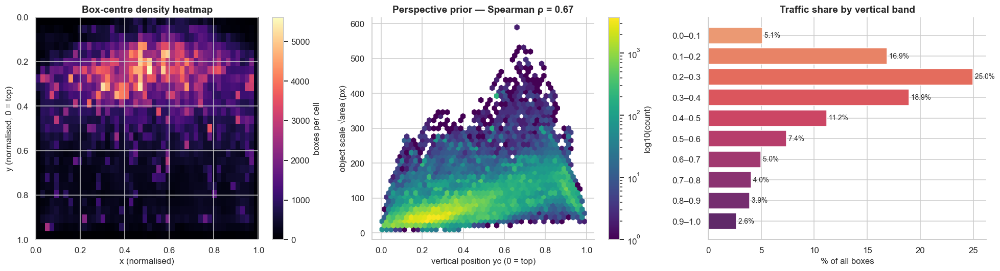

Spearman ρ(yc, √area) = 0.672 | 99 % of vehicles lie between y = 0.02 and y = 0.95


In [12]:
H, xe, ye = np.histogram2d(det["xc"], det["yc"], bins=[48, 27], range=[[0, 1], [0, 1]])
rho = det_s[["yc", "sqrt_area"]].corr(method="spearman").iloc[0, 1]
lo, hi = det["yc"].quantile([.005, .995])
band_pct = pd.cut(det["yc"], np.linspace(0, 1, 11)).value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
im = axes[0].imshow(H.T, extent=[0, 1, 1, 0], aspect="auto", cmap="magma")
axes[0].set_title("Box-centre density heatmap"); axes[0].set_xlabel("x (normalised)"); axes[0].set_ylabel("y (normalised, 0 = top)")
plt.colorbar(im, ax=axes[0], label="boxes per cell")

hb = axes[1].hexbin(det_s["yc"], det_s["sqrt_area"], gridsize=45, bins="log", cmap="viridis", mincnt=1)
axes[1].set_xlabel("vertical position yc (0 = top)"); axes[1].set_ylabel("object scale √area (px)")
axes[1].set_title(f"Perspective prior — Spearman ρ = {rho:.2f}")
plt.colorbar(hb, ax=axes[1], label="log10(count)")

axes[2].barh([f"{iv.left:.1f}–{iv.right:.1f}" for iv in band_pct.index], band_pct.values, color=sns.color_palette("flare", 10))
axes[2].invert_yaxis(); axes[2].set_xlabel("% of all boxes"); axes[2].set_title("Traffic share by vertical band")
for y, v in enumerate(band_pct.values):
    axes[2].text(v, y, f" {v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

FINDINGS.update({"perspective_rho": round(float(rho), 3), "roi_y_low": round(float(lo), 3), "roi_y_high": round(float(hi), 3)})
print(f"Spearman ρ(yc, √area) = {rho:.3f} | 99 % of vehicles lie between y = {lo:.2f} and y = {hi:.2f}")

### 📌 Observation
- **Traffic is concentrated in the upper-middle part of the frame.** The heatmap's brightest cells (above 5,000 boxes per cell) sit at roughly x = 0.35-0.8, y = 0.1-0.4, and the lower 40 % of the frame is sparse. The band chart shows 25.0 % of all boxes in y = 0.2-0.3, **60.8 % in y = 0.1-0.4**, 77.1 % above y = 0.5, and only 10.5 % in the bottom 30 %.
- **The perspective effect is strong: Spearman ρ(yc, √area) = 0.67.** The hexbin's dense core is √area 25-75 px at y = 0.1-0.4, growing to roughly 100-200 px near y = 0.8-0.95, with a maximum near 590 px around y = 0.65.
- 99 % of vehicles lie between y = 0.02 and y = 0.95, i.e. almost the whole frame height.

### 💡 Pipeline / Engineering Decision
- **The ROI-crop idea is dropped:** the 0.5-99.5 % range (y = 0.024-0.949) covers about 92.5 % of the frame height, so cropping would save almost no compute while risking missed vehicles.
- **Vertical flips stay disabled** and random crops/scale jitter are constrained to keep the "far = top, near = bottom" prior; horizontal flips stay enabled.
- **Add a vertical-band evaluation slice:** since 60.8 % of the boxes live in y < 0.4 (the small, far-field band), report AP for y < 0.4 and y ≥ 0.4 separately.
- **Spatial patterns are camera-specific,** so counting lines and violation zones are configured per camera at deployment.

## 🔹 Step 13 — Sequence-Level Leakage Audit & Temporal Redundancy (ACF)

### ❓ Why
UA-DETRAC frames are extracted from video sequences, and consecutive frames are nearly identical. If the same sequence appears in both train and validation, validation is contaminated and metrics are inflated. A stacked bar of frames per sequence by split reveals any overlap directly; the autocorrelation function (ACF) of per-frame object counts quantifies how redundant adjacent frames are.

### 💼 Business Insight
Leakage is the most expensive silent failure in applied ML: the model scores brilliantly in validation, is approved on those numbers, and then underperforms at every new camera in production. Catching it at EDA protects the credibility of every reported metric — and the contract-level SLAs that depend on them.

,sequences,median_frames_per_seq
train,60,1367.5
val,40,1430.0


Sequences shared between train and val: 0  →  ✅ no sequence appears in both splits


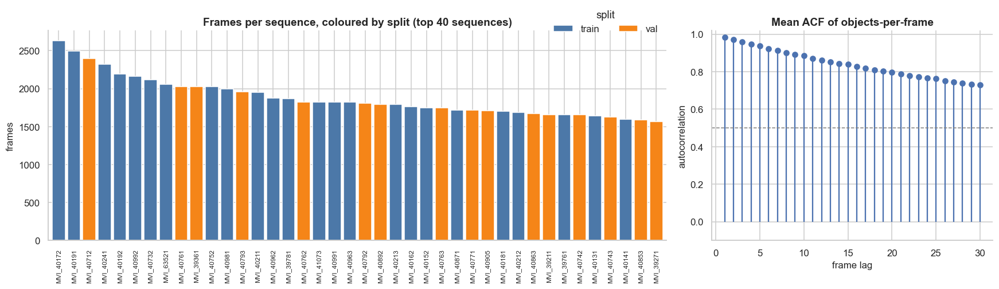

Mean ACF — lag 1: 0.983 | lag 10: 0.885 | suggested training frame stride (ACF < 0.5): 30


In [13]:
has_seq = img_df["sequence"].notna().any()

if not has_seq:
    print("⚠️  No 'MVI_xxxxx' sequence id found in file names — sequence-level audit skipped.")
    FINDINGS["sequence_overlap"] = None; FINDINGS["acf_lag1"] = None; FINDINGS["frame_stride"] = 1
else:
    seq_stats = img_df.groupby(["split", "sequence"]).agg(frames=("image_id", "size"), mean_objs=("n_objects", "mean")).reset_index()
    seq_sets = {sp: set(seq_stats.loc[seq_stats["split"] == sp, "sequence"]) for sp in SPLITS}
    overlap = seq_sets["train"] & seq_sets["val"]

    summary = pd.DataFrame({"sequences": {sp: len(seq_sets[sp]) for sp in SPLITS},
                            "median_frames_per_seq": seq_stats.groupby("split")["frames"].median()})
    display(summary)
    print(f"Sequences shared between train and val: {len(overlap)}  →  "
          + ("⚠️ TEMPORAL LEAKAGE" if overlap else "✅ no sequence appears in both splits"))

    def acf(x, nlags):
        x = np.asarray(x, float); x = x - x.mean(); d = (x ** 2).sum()
        return np.full(nlags, np.nan) if d == 0 else np.array([(x[:-k] * x[k:]).sum() / d for k in range(1, nlags + 1)])

    NLAGS = 30
    acfs = [acf(g.sort_values("frame")["n_objects"].values, NLAGS)
            for _, g in img_df.dropna(subset=["frame"]).groupby(["split", "sequence"]) if len(g) >= 60]
    mean_acf = np.nanmean(acfs, axis=0) if acfs else np.full(NLAGS, np.nan)

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
    pivot = seq_stats.pivot_table(index="sequence", columns="split", values="frames", fill_value=0).reindex(columns=SPLITS, fill_value=0)
    top = pivot.assign(total=pivot.sum(axis=1)).sort_values("total", ascending=False).head(40).drop(columns="total")
    top.plot(kind="bar", stacked=True, ax=axes[0], width=0.85, color=["#4c78a8", "#f58518"])
    axes[0].set_title("Frames per sequence, coloured by split (top 40 sequences)"); axes[0].set_ylabel("frames"); axes[0].set_xlabel("")
    axes[0].tick_params(axis="x", labelrotation=90, labelsize=7.5)
    axes[0].legend(title="split", loc="upper right", bbox_to_anchor=(1.0, 1.14), ncol=2)
    axes[1].stem(range(1, NLAGS + 1), mean_acf, basefmt=" ")
    axes[1].axhline(0.5, color="grey", ls="--", lw=1)
    axes[1].set_title("Mean ACF of objects-per-frame"); axes[1].set_xlabel("frame lag"); axes[1].set_ylabel("autocorrelation"); axes[1].set_ylim(-0.1, 1.02)
    plt.tight_layout(); plt.show()

    stride = next((k + 1 for k, v in enumerate(mean_acf) if v < 0.5), NLAGS)
    FINDINGS["frame_stride"] = int(stride)
    FINDINGS["sequence_overlap"] = len(overlap)
    FINDINGS["n_sequences"] = {sp: len(seq_sets[sp]) for sp in SPLITS}
    FINDINGS["acf_lag1"] = None if np.isnan(mean_acf[0]) else round(float(mean_acf[0]), 3)
    FINDINGS["acf_lag10"] = None if np.isnan(mean_acf[9]) else round(float(mean_acf[9]), 3)
    print(f"Mean ACF — lag 1: {FINDINGS['acf_lag1']} | lag 10: {FINDINGS['acf_lag10']} | suggested training frame stride (ACF < 0.5): {stride}")

### 📌 Observation
- **No sequence appears in both splits: 60 train and 40 val sequences, 0 shared.** In the stacked bars every sequence is a single colour; the 40 longest sequences have about 1,560-2,630 frames each (median 1,367.5 frames in train, 1,430 in val).
- **Neighbouring frames are almost identical:** the mean ACF is 0.983 at lag 1, 0.885 at lag 10 and still about 0.73 at lag 30; the curve never crosses the 0.5 line.
- The printed "suggested stride 30" is therefore **the end of the 30-lag window, not a measured crossing:** the real decorrelation lag is longer than 30 frames (more than about 1.2 s if frames are at 25 fps).

### 💡 Pipeline / Engineering Decision
- **The video-disjoint split is confirmed leakage-free and is kept.** Any future re-split must group by the `MVI_xxxxx` sequence id.
- **Frame sub-sampling:** use a random-offset stride of 10-30 frames per epoch (about 2,800-8,400 train images per epoch). Different offsets across epochs still use all 83,791 frames while avoiding near-duplicates inside an epoch; 30 is a floor, not a tuned value.
- **Effective sample size is about 60 sequences,** not 83,791 images, and the model card says so.
- **Validation is aggregated per sequence** (40 sequences) with a standard error, so one easy video cannot dominate the score; evaluation can use every 10th val frame (about 5,600 images) with little information loss.

## 🔹 Step 14 — Visual Ground-Truth Audit — Sparse, Typical and Dense Scenes

### ❓ Why
Numbers can hide systematic labelling problems that a human eye catches immediately. Sampling images from the 10th, 50th and 90th percentile of scene density and overlaying the ground-truth boxes gives a stratified visual audit rather than a cherry-picked one.

### 💼 Business Insight
Before stakeholders trust a detector, someone has to confirm the annotations match reality. A visual audit is also the most effective communication tool in a stakeholder review — it shows exactly what the system is expected to detect, in scenes the business recognises.

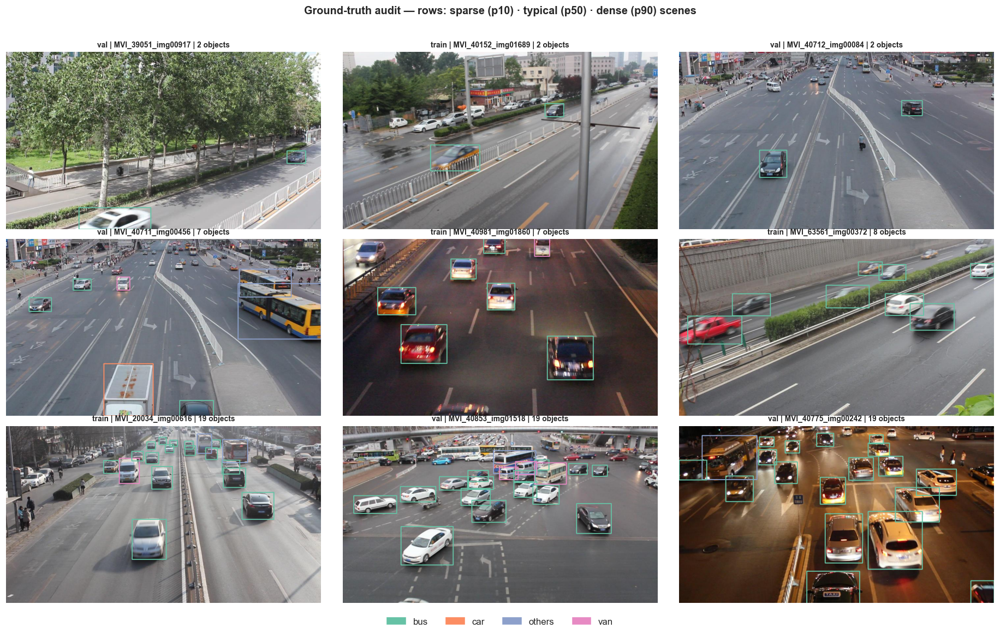

In [14]:
ordered = img_df.sort_values("n_objects").reset_index(drop=True)
rng = np.random.default_rng(SEED)
picks = []
for q in (0.10, 0.50, 0.90):
    centre = int(q * (len(ordered) - 1)); half = max(3, int(0.01 * len(ordered)))
    window = ordered.iloc[max(0, centre - half): centre + half + 1]
    picks += [window.iloc[i] for i in rng.choice(len(window), size=min(3, len(window)), replace=False)]

fig, axes = plt.subplots(3, 3, figsize=(17, 10.5))
for ax, row in zip(axes.ravel(), picks):
    img = read_rgb(row["path"])
    if img is None:
        ax.axis("off"); continue
    h_img, w_img = img.shape[:2]
    boxes = det[(det["split"] == row["split"]) & (det["image_id"] == row["image_id"])]
    for b in boxes.itertuples():
        colour = tuple(int(255 * v) for v in CLASS_PALETTE[b.cls_name])
        p1 = (int((b.xc - b.w / 2) * w_img), int((b.yc - b.h / 2) * h_img))
        p2 = (int((b.xc + b.w / 2) * w_img), int((b.yc + b.h / 2) * h_img))
        cv2.rectangle(img, p1, p2, colour, 2)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{row['split']} | {row['image_id']} | {int(row['n_objects'])} objects", fontsize=9)
fig.legend(handles=[mpatches.Patch(color=CLASS_PALETTE[c], label=c) for c in all_classes],
           loc="lower center", ncol=len(all_classes), fontsize=11)
plt.suptitle("Ground-truth audit — rows: sparse (p10) · typical (p50) · dense (p90) scenes", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]); plt.show()

### 📌 Observation
- **The class names are wrong.** Green boxes (class id 1, shown as "bus") sit on ordinary passenger cars in all nine scenes. A blue-grey box (id 3, "others") is on the articulated yellow city bus, pink boxes (id 2, "van") land on small van/minivan-type vehicles, and the orange box (id 0, "car") is on a large white boxy vehicle. The likely real mapping is 0 = others/truck-type, 1 = car, 2 = van, 3 = bus, **but this is an inference from nine images and must be verified.**
- **Many visible vehicles have no box:** parked cars along the kerb (row 1, centre), distant highway vehicles (row 1, right) and the tiny far-field vehicles at the top of the dense scenes (row 3). This is consistent with UA-DETRAC's ignored regions, which are *not* included in a YOLO export.
- The nine scenes cover daylight, a wet road after rain, dusk/night with headlight glare (row 2 centre, row 3 right), motion blur (row 2 right) and several camera heights. Labeled boxes are tight, and the dense scenes show heavy occlusion.

### 💡 Pipeline / Engineering Decision
- **Fix `CLASS_NAMES` now,** verify with a per-class crop gallery, and regenerate the class weights and the config.
- **Treat unlabeled far-field vehicles as a label-noise risk:** a detector trained on these frames is told that visible vehicles are background. Options, in order of cost: restore the original DETRAC ignore-region masks and zero the loss inside them; otherwise build pseudo-ignore masks from confident detections of a pretrained model that have no ground-truth box; at minimum, do not count detections in those areas as false positives during evaluation.
- **Photometric augmentation targets what is visible here:** night glare, wet-road reflections and motion blur (sized from Step 15).
- **This density-stratified grid becomes a standing QA step** and is reused later to inspect false positives and false negatives of the trained model.

## 🔹 Step 15 — Image Quality — Brightness, Contrast & Sharpness (Sampled)

### ❓ Why
Per-image brightness (mean grey level), contrast (grey-level standard deviation) and sharpness (variance of the Laplacian — a standard blur metric) are cheap proxies for lighting condition, haze/washout and motion blur. KDEs by split show both the operating range and whether train and validation cover the same conditions.

### 💼 Business Insight
Production cameras run day and night in rain and haze. A model trained on a narrow band of lighting conditions will degrade exactly when visibility is worst — and low-visibility hours are when safety and enforcement matter most. Quantifying the lighting range tells us whether the data covers it.

split             train     val
brightness count  600.0   600.0
           mean   110.9   109.6
           std     15.4    15.6
           min     47.1    74.2
           25%    105.9    94.3
           50%    115.6   114.9
           75%    121.0   121.5
           max    135.6   145.7
contrast   count  600.0   600.0
           mean    40.8    47.1
           std      6.1     8.8
           min     24.4    26.8
           25%     36.1    41.8
           50%     40.8    48.1
           75%     45.2    52.3
           max     56.4    72.9
sharpness  count  600.0   600.0
           mean   365.2   543.8
           std    200.1   423.5
           min     25.0    75.9
           25%    214.1   236.1
           50%    389.1   397.0
           75%    511.2   766.3
           max    893.9  2693.4

lighting,dark,normal
split,,
train,2.8,97.2
val,0.0,100.0


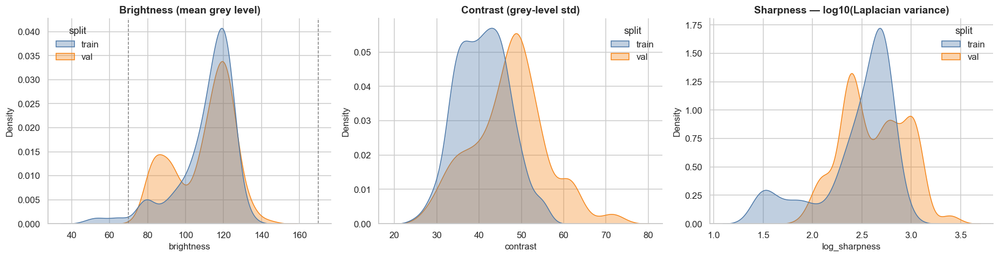

Dark frames: 1.4% | Bright frames: 0.0% | brightness p5–p95: (80.5, 127.5)


In [15]:
def gray_quality(path):
    g = read_bgr(path, cv2.IMREAD_GRAYSCALE)
    if g is None:
        return None
    return {"brightness": float(g.mean()), "contrast": float(g.std()),
            "sharpness": float(cv2.Laplacian(g, cv2.CV_64F).var())}

q_rows = []
for sp in SPLITS:
    for p in DETRAC_SAMPLE[sp]:
        r = gray_quality(p)
        if r: q_rows.append({"split": sp, "image_id": p.stem, **r})
quality_df = pd.DataFrame(q_rows).merge(img_df[["split", "image_id", "n_objects"]], on=["split", "image_id"], how="left")
quality_df["log_sharpness"] = np.log10(quality_df["sharpness"] + 1)

DARK_T, BRIGHT_T = 70, 170
quality_df["lighting"] = pd.cut(quality_df["brightness"], [-1, DARK_T, BRIGHT_T, 256], labels=["dark", "normal", "bright"])
display(quality_df.groupby("split")[["brightness", "contrast", "sharpness"]].describe().round(1).T)
light_pct = (pd.crosstab(quality_df["split"], quality_df["lighting"], normalize="index") * 100).round(1)
display(light_pct)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["brightness", "contrast", "log_sharpness"],
                          ["Brightness (mean grey level)", "Contrast (grey-level std)", "Sharpness — log10(Laplacian variance)"]):
    sns.kdeplot(data=quality_df, x=col, hue="split", fill=True, common_norm=False, alpha=.35, ax=ax, palette=["#4c78a8", "#f58518"])
    ax.set_title(title)
axes[0].axvline(DARK_T, color="grey", ls="--", lw=1); axes[0].axvline(BRIGHT_T, color="grey", ls="--", lw=1)
plt.tight_layout(); plt.show()

FINDINGS.update({"dark_pct": float(quality_df["lighting"].eq("dark").mean() * 100),
                 "bright_pct": float(quality_df["lighting"].eq("bright").mean() * 100),
                 "brightness_range": (round(float(quality_df["brightness"].quantile(.05)), 1), round(float(quality_df["brightness"].quantile(.95)), 1)),
                 "detrac_median_sharpness": round(float(quality_df["sharpness"].median()), 1),
                 "detrac_median_brightness": round(float(quality_df["brightness"].median()), 1)})
print(f"Dark frames: {FINDINGS['dark_pct']:.1f}% | Bright frames: {FINDINGS['bright_pct']:.1f}% | brightness p5–p95: {FINDINGS['brightness_range']}")

### 📌 Observation
- **Brightness is narrow and nearly identical in the centre:** both splits peak near 120 (median 115.6 train, 114.9 val; p5-p95 of the pooled sample 80.5-127.5). Dark frames (< 70) are 2.8 % of train and 0 % of val; there are no bright frames (> 170).
- **Val has a second brightness mode near 85** (dusk/overcast scenes) that train barely has (a small bump near 80 and a thin tail near 55).
- **Contrast is higher in val:** median 48.1 against 40.8, maximum 72.9 against 56.4.
- **Sharpness differs in shape:** val is wider and bimodal (peaks near log10 2.4 and 3.0; standard deviation 423.5 against 200.1; maximum 2,693 against 894), while train has a tail of very blurry frames near log10 1.5 (minimum 25.0) that val lacks (minimum 75.9).

### 💡 Pipeline / Engineering Decision
- **Train and val differ in image statistics as well as in class mix,** which fits the scene-level shift found in Step 7.
- **Photometric ranges come from these numbers:** brightness/value jitter of about 0.5-1.3× (observed 47-146 around a median of 115), contrast jitter of about ±30 % (val is 18 % higher than train), plus mild Gaussian/motion blur and a sharpening augmentation, because train and val sit on opposite sides of the sharpness distribution.
- **Night is under-represented (about 1.4 % of sampled frames),** so night robustness cannot be claimed from this training set: if night operation is a requirement, oversample dark frames and report a dark-frame evaluation slice.
- **Drift monitor:** log live-frame brightness against the training band (mean about 110, standard deviation about 15.5, p5-p95 80.5-127.5) and alert when a camera leaves it.

## 🔹 Step 16 — Image-Level Feature Correlation Heatmap

### ❓ Why
A Spearman correlation matrix between scene density, mean object size, small-object share and the three quality metrics shows which factors move together. Spearman is used because the relationships are monotonic but not linear and the variables are skewed.

### 💼 Business Insight
Understanding feature interactions prevents wrong conclusions: if dense scenes are also the blurrier or darker ones, a recall drop in dense traffic might actually be a low-light problem. Disentangling these factors tells the team where to invest — more data, better augmentation or a better camera.

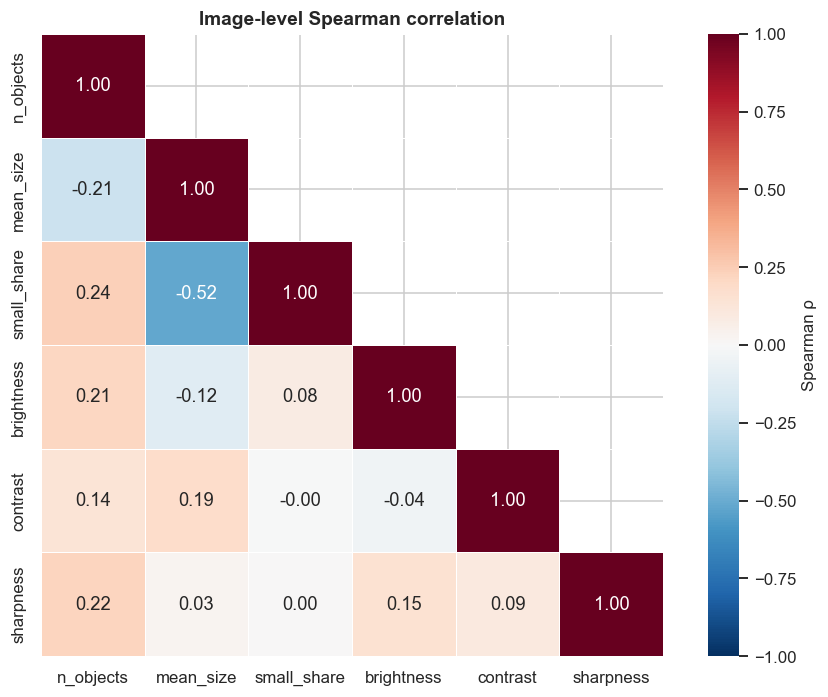

,feature_a,feature_b,rho
2,small_share,mean_size,-0.517
1,small_share,n_objects,0.239
10,sharpness,n_objects,0.222
0,mean_size,n_objects,-0.212
3,brightness,n_objects,0.211


In [16]:
box_feat = det.groupby(["split", "image_id"]).agg(mean_size=("sqrt_area", "mean"), small_share=("is_small", "mean")).reset_index()
corr_df = quality_df.merge(box_feat, on=["split", "image_id"], how="left").dropna(subset=["mean_size"])
FEATS = ["n_objects", "mean_size", "small_share", "brightness", "contrast", "sharpness"]
corr = corr_df[FEATS].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=.5, square=True,
            cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("Image-level Spearman correlation")
plt.tight_layout(); plt.show()

pairs = corr.where(~mask & ~np.eye(len(corr), dtype=bool)).stack().rename("rho").reset_index()
pairs.columns = ["feature_a", "feature_b", "rho"]
top_pairs = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(5).round(3)
display(top_pairs)
FINDINGS["top_corr_pair"] = tuple(top_pairs.iloc[0][["feature_a", "feature_b"]]) + (float(top_pairs.iloc[0]["rho"]),)

### 📌 Observation
- **The only moderate correlation is small_share vs mean_size (ρ = -0.52),** which is largely mechanical because the small-object share is computed from object size.
- **Everything involving scene density is weak:** n_objects with small_share +0.24, sharpness +0.22, brightness +0.21, mean_size -0.21 and contrast +0.14.
- **Quality-to-quality correlations are all small:** brightness-sharpness 0.15, contrast-sharpness 0.09, brightness-contrast -0.04.
- Denser frames are slightly brighter and sharper, i.e. busy scenes are mostly clear daytime scenes, not dark or blurry ones.

### 💡 Pipeline / Engineering Decision
- **No strong confounding exists,** so density, object size and lighting are evaluated as independent slices rather than one combined factor.
- **A "dense and small" joint slice must be defined explicitly** (for example 23 or more objects per frame and an above-median small-object share), because the factors are only weakly coupled (ρ = 0.24) and the joint slice is not simply the union of the two.
- **No feature pruning is needed,** and no meta-model uses these features today.
- **The correlations come from 1,200 sampled frames** (600 per split), which is enough for a ranking of effects but not for fine decimals.

## 🔹 Step 17 — Occlusion & Box Overlap — Max-IoU per Box (NMS Calibration)

### ❓ Why
For every box, the maximum IoU with any *other* box in the same image measures how occluded or crowded that vehicle is. The distribution (histogram + ECDF) and its dependence on scene density give a data-driven basis for choosing the NMS IoU threshold — the single post-processing parameter that trades duplicate suppression against merged vehicles.

### 💼 Business Insight
In congested traffic, a too-aggressive NMS fuses two adjacent vehicles into one detection (under-counting); a too-lenient NMS produces double detections (over-counting). Either error corrupts vehicle counts, queue-length estimates and any enforcement that depends on unique vehicle identity.

,IoU threshold,% boxes overlapped above threshold
0,0.3,2.87
1,0.5,0.32
2,0.7,0.03


,mean_max_iou,share_gt_05
bin,,
2–5,0.023,0.599
6–10,0.044,0.637
11–20,0.069,0.075
21–40,0.120,0.133
40+,NaN,NaN


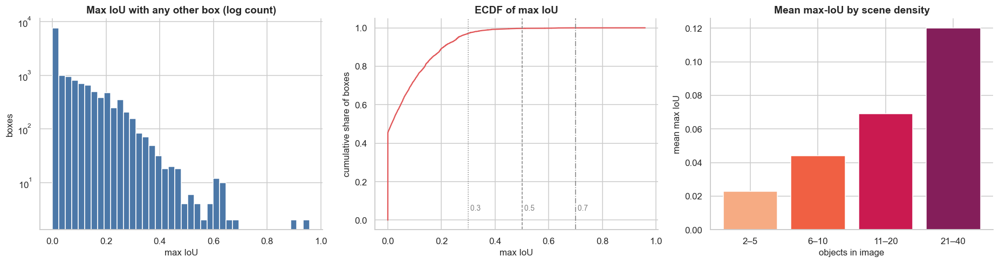

0.32% of boxes overlap another box by IoU > 0.5 → recommended NMS IoU = 0.55


In [17]:
def max_iou_per_box(xyxy):
    x1 = np.maximum(xyxy[:, None, 0], xyxy[None, :, 0]); y1 = np.maximum(xyxy[:, None, 1], xyxy[None, :, 1])
    x2 = np.minimum(xyxy[:, None, 2], xyxy[None, :, 2]); y2 = np.minimum(xyxy[:, None, 3], xyxy[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])
    iou = inter / (area[:, None] + area[None, :] - inter + 1e-9)
    np.fill_diagonal(iou, 0)
    return iou.max(axis=1)

multi = img_df[img_df["n_objects"] >= 2]
sample_imgs = multi.sample(min(1500, len(multi)), random_state=SEED)[["split", "image_id"]]
sub = det.merge(sample_imgs, on=["split", "image_id"])

max_ious, density = [], []
for _, g in sub.groupby(["split", "image_id"]):
    cx, cy = g["xc"].values * IMG_W, g["yc"].values * IMG_H
    bw, bh = g["w_px"].values, g["h_px"].values
    xyxy = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], axis=1)
    m = max_iou_per_box(xyxy)
    max_ious.append(m); density.append(np.full(len(m), len(g)))
max_ious, density = np.concatenate(max_ious), np.concatenate(density)

share = {t: float((max_ious > t).mean() * 100) for t in (0.3, 0.5, 0.7)}
display(pd.DataFrame({"IoU threshold": list(share), "% boxes overlapped above threshold": np.round(list(share.values()), 2)}))
bins = pd.cut(density, [1, 5, 10, 20, 40, np.inf], labels=["2–5", "6–10", "11–20", "21–40", "40+"])
by_density = pd.DataFrame({"max_iou": max_ious, "bin": bins}).groupby("bin").agg(mean_max_iou=("max_iou", "mean"),
                                                                              share_gt_05=("max_iou", lambda s: (s > .5).mean() * 100)).round(3)
display(by_density)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].hist(max_ious, bins=40, color="#4c78a8"); axes[0].set_yscale("log")
axes[0].set_title("Max IoU with any other box (log count)"); axes[0].set_xlabel("max IoU"); axes[0].set_ylabel("boxes")
v = np.sort(max_ious); axes[1].plot(v, np.arange(1, len(v) + 1) / len(v), color="#e15759")
for t, ls in zip((0.3, 0.5, 0.7), (":", "--", "-.")):
    axes[1].axvline(t, color="grey", ls=ls, lw=1); axes[1].text(t, 0.05, f" {t}", fontsize=9, color="grey")
axes[1].set_title("ECDF of max IoU"); axes[1].set_xlabel("max IoU"); axes[1].set_ylabel("cumulative share of boxes")
axes[2].bar(by_density.index.astype(str), by_density["mean_max_iou"], color=sns.color_palette("rocket_r", len(by_density)))
axes[2].set_title("Mean max-IoU by scene density"); axes[2].set_xlabel("objects in image"); axes[2].set_ylabel("mean max IoU")
plt.tight_layout(); plt.show()

nms_iou = 0.70 if share[0.5] > 5 else 0.55
FINDINGS.update({"overlap_gt05_pct": round(share[0.5], 2), "overlap_gt03_pct": round(share[0.3], 2), "nms_iou": nms_iou})
print(f"{share[0.5]:.2f}% of boxes overlap another box by IoU > 0.5 → recommended NMS IoU = {nms_iou}")

### 📌 Observation
- **Overlap among labeled boxes is rare.** About 45 % of boxes have no overlap at all (the ECDF starts near 0.45 at max IoU = 0), and 2.87 % overlap another box by IoU > 0.3, **0.32 % by IoU > 0.5** and 0.03 % by IoU > 0.7. The histogram decays roughly exponentially to about 0.65, with only a couple of boxes at 0.9-0.95.
- **Overlap rises with density:** mean max-IoU is 0.023 (2-5 objects), 0.044 (6-10), 0.069 (11-20) and 0.120 (21-40), a fivefold increase. The 40+ bin is empty because the 1,500-frame sample contains no frame with more than 40 objects.

### 💡 Pipeline / Engineering Decision
- **NMS IoU = 0.55** is selected (0.32 % is far below the 5 % rule). Because real vehicles seldom overlap by more than 0.5, a threshold near 0.5-0.55 rarely merges two true vehicles and suppresses duplicate predictions more strongly than the common 0.7 default.
- **Validate, don't assume:** sweep NMS IoU over 0.45, 0.55, 0.65 and 0.70 on val and choose by AP on the crowded slice (23 or more objects).
- **Add a near-duplicate rule (IoU > 0.9, same image) to the validator** and inspect the handful of boxes at 0.9-0.95; they are not exact duplicates, so Step 5 did not flag them.
- **Occlusion is mild in the labels, but unlabeled vehicles hide the true crowding** (Step 14); the metric is therefore a lower bound on real overlap.

## 🔹 Step 18 — Anchor / Scale Prior Fit — K-Means on Box (w, h) with IoU Metric

### ❓ Why
K-means clustering on box width/height with an IoU-based fit metric (the YOLO-style anchor method) summarises the scale space in a few representative sizes. The elbow curve (mean best-IoU vs number of clusters) shows how many priors are enough; the cluster scatter shows the shape of the scale space.

### 💼 Business Insight
Well-matched scale priors make training converge faster and reach higher recall on small and unusual vehicles, which shortens experiment cycles (less GPU time per iteration) and improves detection quality at no inference cost.

,w_px_native,h_px_native,w_at_640,h_at_640
0,36.1,28.2,24.1,18.8
1,59.8,42.7,39.9,28.5
2,89.6,46.6,59.7,31.1
3,87.8,88.9,58.5,59.3
4,125.0,64.0,83.3,42.7
5,164.8,85.2,109.9,56.8
6,138.2,139.4,92.1,92.9
7,212.0,113.4,141.4,75.6
8,283.3,122.9,188.8,82.0
9,200.8,259.7,133.9,173.1


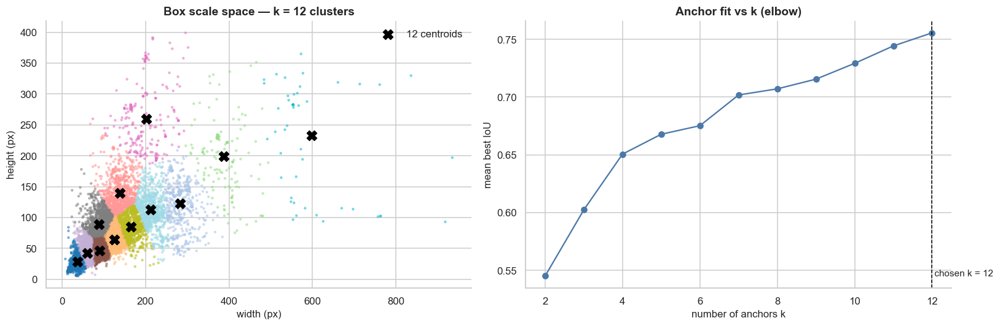

Chosen k = 12 | mean best-IoU = 0.756


In [18]:
wh = det[["w_px", "h_px"]].sample(min(len(det), 100_000), random_state=SEED).values

def wh_iou(boxes, centres):
    inter = np.minimum(boxes[:, None, 0], centres[None, :, 0]) * np.minimum(boxes[:, None, 1], centres[None, :, 1])
    union = boxes[:, 0:1] * boxes[:, 1:2] + (centres[:, 0] * centres[:, 1])[None, :] - inter
    return inter / union

KS = list(range(2, 13)); mean_best, models = [], {}
for k in KS:
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(wh)
    models[k] = km; mean_best.append(float(wh_iou(wh, km.cluster_centers_).max(axis=1).mean()))

best_k = KS[-1]
for i in range(len(KS) - 1):
    if mean_best[i + 1] - mean_best[i] < 0.005:      # <0.5 pt gain from one more anchor → stop
        best_k = KS[i]; break

km = models[best_k]
anchors = km.cluster_centers_[np.argsort(km.cluster_centers_.prod(axis=1))]
scale = FINDINGS["rec_imgsz"] / max(IMG_W, IMG_H)
anchor_table = pd.DataFrame({"w_px_native": anchors[:, 0].round(1), "h_px_native": anchors[:, 1].round(1),
                             f"w_at_{FINDINGS['rec_imgsz']}": (anchors[:, 0] * scale).round(1),
                             f"h_at_{FINDINGS['rec_imgsz']}": (anchors[:, 1] * scale).round(1)})
display(anchor_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
view = np.random.default_rng(SEED).choice(len(wh), size=min(20_000, len(wh)), replace=False)
axes[0].scatter(wh[view, 0], wh[view, 1], c=km.labels_[view], cmap="tab20", s=4, alpha=.45)
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="black", marker="X", s=110, label=f"{best_k} centroids")
axes[0].set_xlabel("width (px)"); axes[0].set_ylabel("height (px)"); axes[0].set_title(f"Box scale space — k = {best_k} clusters"); axes[0].legend()
axes[1].plot(KS, mean_best, marker="o", color="#4c78a8")
axes[1].axvline(best_k, color="black", ls="--", lw=1); axes[1].text(best_k, min(mean_best), f" chosen k = {best_k}", fontsize=10)
axes[1].set_xlabel("number of anchors k"); axes[1].set_ylabel("mean best IoU"); axes[1].set_title("Anchor fit vs k (elbow)")
plt.tight_layout(); plt.show()

FINDINGS.update({"best_k": best_k, "mean_best_iou": round(mean_best[KS.index(best_k)], 3),
                 "anchors_native": anchors.round(1).tolist()})
print(f"Chosen k = {best_k} | mean best-IoU = {FINDINGS['mean_best_iou']}")

### 📌 Observation
- **The (width, height) cloud is one continuous diagonal band, not separated clusters.** Most mass lies at 25-300 px wide and 20-200 px high, with a sparse scatter out to about 900×400 px. The 12 centroids run from 36×28 px to 597×234 px, a 17× spread in width.
- **The elbow curve never flattens:** mean best-IoU is 0.545 (k = 2), 0.650 (k = 4), 0.702 (k = 7), 0.729 (k = 10) and 0.756 (k = 12). The gain from 11 to 12 anchors (0.011) still exceeds the 0.005 stop rule, so **k = 12 is simply the largest value tested**, not an elbow.
- Even with 12 anchors the mean best-IoU is only 0.756, i.e. the scale space is too continuous for a small anchor set. At 640 px input the anchors run from about 24×19 px to 398×156 px.

### 💡 Pipeline / Engineering Decision
- **Use an anchor-free detector (YOLOv8/11) by default:** a 12-anchor fit with mean best-IoU 0.756 is a weak fit, and no anchor count gives a clear elbow.
- **If an anchor-based model is required,** use the standard 9 anchors (3 per level, mean best-IoU about 0.72) and re-run k-means whenever the input size or camera set changes; the table in this step lists the values at both native and 640 px resolution.
- **The anchor analysis is kept as a scale-coverage check:** the smallest anchor at 640 px (about 24×19 px) is consistent with the 640 px input chosen in Step 11.

# 🅒 Part C — Indian Number Plates (Plate Detection & Recognition)

## 🔹 Step 19 — Plate Dataset Inventory — Images, XML Annotations & Pairing

### ❓ Why
This dataset has two file types that must be paired — photographs and Pascal-VOC XML annotation files. A bar chart of images, annotations, matched pairs and orphans shows the usable labelled set in one glance, and the file-size histogram flags unusually small (heavily compressed) or huge images.

### 💼 Business Insight
The usable training set is the *matched* set, not the raw image count. For a plate-recognition capability that will eventually be tied to legal evidence (e-challan), the number of verified, annotated plates is the real asset — and its size determines how much accuracy we can credibly promise.

,count
images,47
xml_annotations,47
matched_pairs,47
images_without_xml,0
xml_without_image,0


,images,with_xml
detection_set (boxes only),27,27
ocr_set (boxes + text),20,20


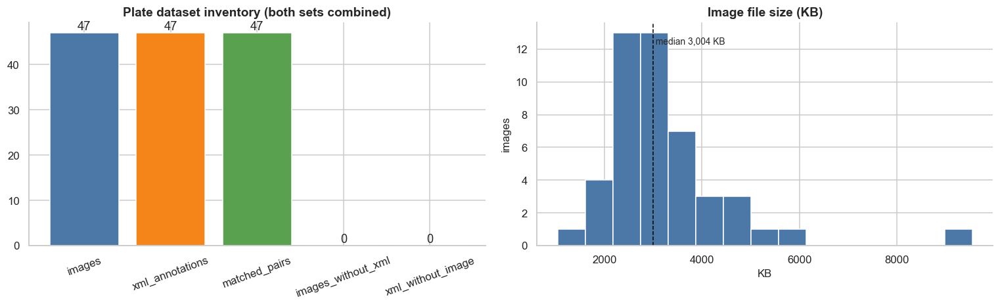

In [19]:
SOURCE_OF, plate_images = {}, []
for d, set_name in zip(PLATE_IMG_DIRS, PLATE_SET_NAMES):
    for p in list_files(d, IMG_EXT):
        SOURCE_OF[p.stem] = set_name
        plate_images.append(p)
plate_xmls = [p for d in PLATE_ANN_DIRS for p in list_files(d, {".xml"})]
if not plate_images:
    raise FileNotFoundError(f"No plate images found in {PLATE_IMG_DIRS}")
assert len({p.stem for p in plate_images}) == len(plate_images), "Duplicate file names across the two plate sets"

img_stems, xml_stems = {p.stem for p in plate_images}, {p.stem for p in plate_xmls}
matched = img_stems & xml_stems
inv = pd.Series({
    "images": len(img_stems), "xml_annotations": len(xml_stems), "matched_pairs": len(matched),
    "images_without_xml": len(img_stems - xml_stems), "xml_without_image": len(xml_stems - img_stems),
})
display(inv.to_frame("count"))

per_set = pd.DataFrame({
    "images":   pd.Series(SOURCE_OF).value_counts(),
    "with_xml": pd.Series({s: SOURCE_OF[s] for s in matched}).value_counts(),
}).fillna(0).astype(int)
display(per_set)

size_kb = np.array([p.stat().st_size / 1024 for p in plate_images])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].bar(inv.index, inv.values, color=["#4c78a8", "#f58518", "#59a14f", "#e15759", "#b07aa1"])
axes[0].set_title("Plate dataset inventory (both sets combined)"); axes[0].tick_params(axis="x", labelrotation=20)
for i, v in enumerate(inv.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].hist(size_kb, bins=min(30, max(5, len(size_kb) // 3)), color="#4c78a8")
axes[1].set_title("Image file size (KB)"); axes[1].set_xlabel("KB"); axes[1].set_ylabel("images")
axes[1].axvline(np.median(size_kb), color="black", ls="--", lw=1)
axes[1].text(np.median(size_kb), axes[1].get_ylim()[1] * .9, f" median {np.median(size_kb):,.0f} KB", fontsize=9)
plt.tight_layout(); plt.show()

FINDINGS.update({"n_plate_images": len(img_stems), "n_plate_pairs": len(matched), "plate_median_kb": round(float(np.median(size_kb)), 1)})

### 📌 Observation
- **47 images, 47 XML files and 47 matched pairs, with 0 orphans in either direction.** The set splits into a **detection set of 27 images** (27 XMLs, boxes only) and an **OCR set of 20 images** (20 XMLs, boxes plus plate text); no file name appears in both sets.
- The inventory bars read 47 / 47 / 47 / 0 / 0, and the average file is large (about 3.2-3.5 MB per image, from the folder sizes in Step 2), as expected for phone-camera JPEGs.
- This is about 0.03 % of the number of images in UA-DETRAC (47 against roughly 140,000).

### 💡 Pipeline / Engineering Decision
- **Both plate folders are merged into one table with a `source` column** (assertion on duplicate file names passed), so the detection set and the OCR set remain separable for training and evaluation.
- **47 images is a proof-of-concept scale:** plate recognition cannot be trained from scratch on it. Plan: a pretrained detector fine-tuned on these images, a pretrained or synthetically trained OCR, and these 47 images used mainly as a *test set* until more data is collected.
- **Use cross-validation instead of a fixed split** (for example leave-one-out or 5-fold grouped by plate string) so that no tiny validation set decides the model.
- **Resize on load:** images are 3.7-15.9 MP, so cap the long side (about 1280 px) in the loader to avoid a data-loading bottleneck.

## 🔹 Step 20 — Parsing Pascal-VOC XML into a Plate DataFrame

### ❓ Why
XML cannot be analysed directly. Parsing every annotation into one row per plate (`image size, label, xmin/ymin/xmax/ymax, plate text`) lets us compute geometry and text statistics with group-bys. The parser deliberately accepts several attribute layouts for the plate text (a dedicated tag, or a name/value `attribute` element) because annotation tools export this differently.

### 💼 Business Insight
The plate text field is the ground truth for recognition (OCR) and is what ultimately becomes an enforcement record. Verifying that it is present, parseable and attached to the right box is a pre-condition for any recognition KPI — no label, no measurable accuracy.

Parsed 52 annotated objects from 47 XML files | XML parse errors: 0


,stem,img_w,img_h,label,xmin,ymin,xmax,ymax,plate_text,source,bw,bh,aspect,rel_area,cx_rel,cy_rel
0,Datacluster_number_plates (1),2448,3264,number_plate,382.75,1106.90,1147.75,1718.95,None,detection_set (boxes only),765.00,612.05,1.249898,0.058599,0.312602,0.432881
1,Datacluster_number_plates (101),1968,4144,number_plate,860.92,1210.57,1573.17,1501.94,None,detection_set (boxes only),712.25,291.37,2.444486,0.025447,0.618417,0.327282
2,Datacluster_number_plates (11),1440,2560,number_plate,248.00,992.00,1308.00,1604.00,None,detection_set (boxes only),1060.00,612.00,1.732026,0.175977,0.540278,0.507031
3,Datacluster_number_plates (16),4000,3000,number_plate,1329.53,1687.66,2388.91,1978.30,None,detection_set (boxes only),1059.38,290.64,3.644990,0.025658,0.464805,0.610993
4,Datacluster_number_plates (18),3000,4000,number_plate,943.75,1012.50,1825.00,1343.75,None,detection_set (boxes only),881.25,331.25,2.660377,0.024326,0.461458,0.294531
5,Datacluster_number_plates (22),3000,4000,number_plate,900.00,1337.50,1687.50,1625.00,None,detection_set (boxes only),787.50,287.50,2.739130,0.018867,0.431250,0.370312
6,Datacluster_number_plates (36),3000,4000,number_plate,868.75,1000.00,2250.00,1912.50,None,detection_set (boxes only),1381.25,912.50,1.513699,0.105033,0.519792,0.364063
7,Datacluster_number_plates (38),3024,4032,number_plate,964.10,1354.66,1946.86,1568.90,None,detection_set (boxes only),982.76,214.24,4.587192,0.017268,0.481310,0.362545


,boxes,with_text
source,,
detection_set (boxes only),27,0
ocr_set (boxes + text),25,25


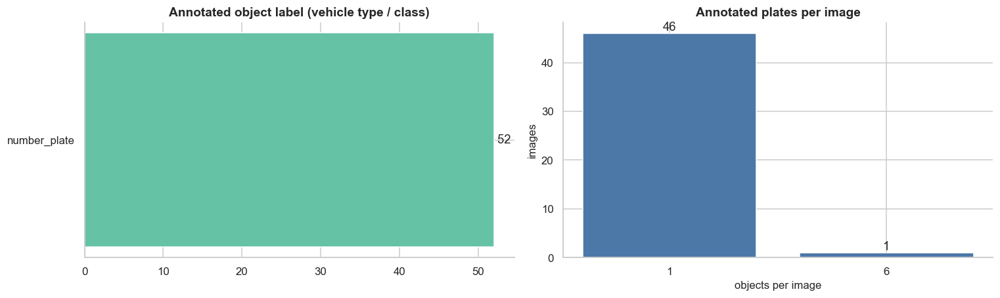

Plate-text present for 48.1% of boxes


In [20]:
def _t(el):
    return (el.text or "").strip() if el is not None else ""

def _strip_ns(root):
    for el in root.iter():
        if isinstance(el.tag, str):
            el.tag = el.tag.split("}")[-1]          # remove XML namespaces

def extract_plate_text(obj):
    # supports <number_plate_text>, <attribute name="number_plate_text">, <attribute><name/><value/></attribute>
    for el in obj.iter():
        tag = el.tag.lower()
        if tag in {"number_plate_text", "plate_text"} and _t(el):
            return _t(el)
        if tag == "attribute":
            nm = (el.get("name") or el.findtext("name") or "").strip().lower()
            if nm in {"number_plate_text", "plate_text", "text"}:
                val = _t(el) or (el.findtext("value") or "").strip()
                if val:
                    return val
    return None

BOX_KEYS = {"xmin", "ymin", "xmax", "ymax"}

def parse_voc(path):
    root = ET.parse(path).getroot()
    _strip_ns(root)
    parent = {c: p for p in root.iter() for c in p}
    W = int(float(root.findtext(".//size/width") or root.findtext(".//width") or 0))
    H = int(float(root.findtext(".//size/height") or root.findtext(".//height") or 0))
    out = []
    for box in root.iter():                       # a "box" = any element holding xmin/ymin/xmax/ymax children
        kids = {c.tag.lower(): c for c in box}
        if not BOX_KEYS.issubset(kids):
            continue
        obj = parent.get(box, root)
        label = (obj.findtext("name") or "").strip() if obj is not root else ""
        out.append({"stem": path.stem, "img_w": W, "img_h": H, "label": label or "unlabelled",
                    "xmin": float(_t(kids["xmin"])), "ymin": float(_t(kids["ymin"])),
                    "xmax": float(_t(kids["xmax"])), "ymax": float(_t(kids["ymax"])),
                    "plate_text": extract_plate_text(obj)})
    return out

plate_rows, parse_errors, objs_per_xml = [], [], {}
for xp in plate_xmls:
    try:
        objs = parse_voc(xp)
    except Exception as e:                       # malformed XML must not stop the audit
        parse_errors.append((xp.name, repr(e))); continue
    objs_per_xml[xp.stem] = len(objs); plate_rows += objs

if not plate_rows:
    print(f"XML files found: {len(plate_xmls)} | parse errors: {len(parse_errors)}")
    for name, err in parse_errors[:5]:
        print("  parse error ->", name, err)
    if plate_xmls:
        print("\nFirst XML file:", plate_xmls[0])
        print(plate_xmls[0].read_text(errors="ignore")[:1500])
    raise ValueError("No bounding boxes could be parsed from the plate XML files.")

plates_df = pd.DataFrame(plate_rows)
plates_df["source"] = plates_df["stem"].map(SOURCE_OF)

img_lookup = {p.stem: p for p in plate_images}
for stem in plates_df.loc[plates_df["img_w"] <= 0, "stem"].unique():       # fall back to the real image size
    if stem in img_lookup:
        with Image.open(img_lookup[stem]) as im:
            plates_df.loc[plates_df["stem"] == stem, "img_w"] = im.size[0]
            plates_df.loc[plates_df["stem"] == stem, "img_h"] = im.size[1]

plates_df["bw"] = plates_df["xmax"] - plates_df["xmin"]
plates_df["bh"] = plates_df["ymax"] - plates_df["ymin"]
plates_df["aspect"] = plates_df["bw"] / plates_df["bh"].replace(0, np.nan)
plates_df["rel_area"] = (plates_df["bw"] * plates_df["bh"]) / (plates_df["img_w"] * plates_df["img_h"]).replace(0, np.nan)
plates_df["cx_rel"] = (plates_df["xmin"] + plates_df["xmax"]) / 2 / plates_df["img_w"].replace(0, np.nan)
plates_df["cy_rel"] = (plates_df["ymin"] + plates_df["ymax"]) / 2 / plates_df["img_h"].replace(0, np.nan)

print(f"Parsed {len(plates_df):,} annotated objects from {plates_df['stem'].nunique():,} XML files | XML parse errors: {len(parse_errors)}")
display(plates_df.head(8))
display(plates_df.groupby("source").agg(boxes=("stem", "size"), with_text=("plate_text", lambda s: int(s.notna().sum()))))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
lab = plates_df["label"].value_counts()
axes[0].barh(lab.index, lab.values, color=sns.color_palette("Set2", len(lab))); axes[0].invert_yaxis()
axes[0].set_title("Annotated object label (vehicle type / class)")
for y, v in enumerate(lab.values):
    axes[0].text(v, y, f" {v}", va="center")
opi = pd.Series(objs_per_xml).value_counts().sort_index()
axes[1].bar(opi.index.astype(str), opi.values, color="#4c78a8"); axes[1].set_title("Annotated plates per image")
axes[1].set_xlabel("objects per image"); axes[1].set_ylabel("images")
for i, v in enumerate(opi.values):
    axes[1].text(i, v, f"{v}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

FINDINGS.update({"n_plate_boxes": int(len(plates_df)), "plate_parse_errors": len(parse_errors),
                 "plate_text_present_pct": round(float(plates_df["plate_text"].notna().mean() * 100), 1),
                 "plate_label_counts": lab.to_dict()})
print(f"Plate-text present for {FINDINGS['plate_text_present_pct']}% of boxes")

### 📌 Observation
- **52 plate boxes were parsed from 47 XML files with 0 parse errors, and all 52 share one label, `number_plate`.** The label chart is therefore a single bar, and the dataset carries no vehicle-type information.
- **46 images contain exactly one plate and one image contains six** (46 + 6 = 52 boxes).
- **Plate text exists for 25 of 52 boxes (48.1 %): all 25 are in the OCR set** (25 boxes across 20 images) and none of the 27 detection-set boxes has text.
- The head of the table shows images of 2448×3264, 1968×4144 and 4000×3000 px with plates roughly 700-1,380 px wide in the first rows, i.e. large images with plates covering 1.7-17.6 % of the frame.

### 💡 Pipeline / Engineering Decision
- **A single-class plate detector** (`number_plate`) is trained here; vehicle type comes from Stage 1 on UA-DETRAC.
- **Two evaluation tracks:** detection mAP on all 47 images (52 boxes), and OCR exact-match on the 25 transcribed boxes. Detection-set boxes are used for detection only and excluded from OCR training and OCR evaluation.
- **Transcribe the 27 missing plate texts:** it is a small manual job that would raise the OCR set from 25 to 52 strings (×2.1).
- **The six-plate image is kept together in one fold,** so its plates can never be split between train and validation.

## 🔹 Step 21 — Annotation Integrity & Label-Quality Audit

### ❓ Why
Plate-level checks parallel the DETRAC audit but add text-specific ones: inverted/degenerate boxes, boxes outside the image, very small plates, missing text, images with several plates and repeated plate strings (possible duplicate vehicles). Each check is shown as a count so the cleaning budget is explicit.

### 💼 Business Insight
With a small dataset, every bad annotation is a large fraction of the signal. A single wrong plate string is a mislabelled training example for recognition and — in production — the difference between fining the right owner and the wrong one. Quality here is a legal and reputational issue, not just a modelling one.

,check,count,severity,pct_of_boxes
0,XML files that failed to parse,0,Critical,0.00
1,Images without annotation,0,Warning,0.00
2,Annotation files without image,0,Critical,0.00
3,Inverted / zero-area boxes,0,Critical,0.00
4,Boxes outside image bounds,0,Critical,0.00
5,Very small plates (width < 40 px),1,Warning,1.92
6,Boxes without plate text,27,Warning,51.92
7,Images with more than one plate,1,Info,1.92
8,Repeated plate strings (possible duplicates),1,Warning,1.92


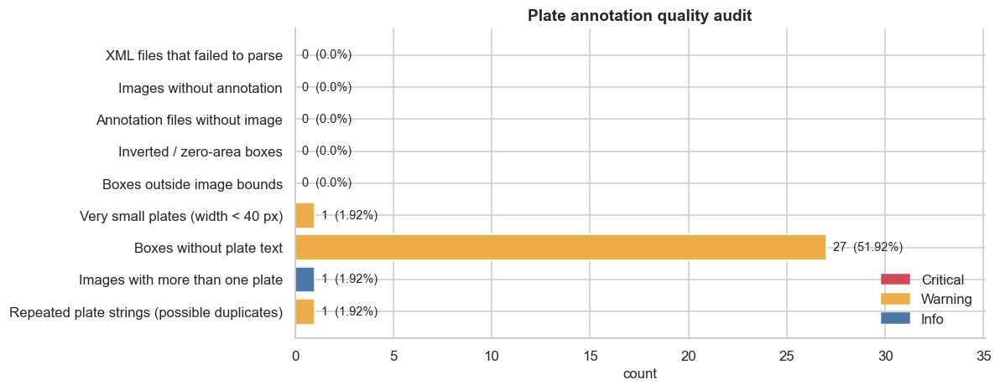

Critical defects: 0 | boxes without text: 27


In [21]:
norm_text = plates_df["plate_text"].dropna().str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
norm_text = norm_text[norm_text != ""]

checks = pd.DataFrame([
    ("XML files that failed to parse",                 len(parse_errors),                                                                  "Critical"),
    ("Images without annotation",                      len(img_stems - xml_stems),                                                         "Warning"),
    ("Annotation files without image",                 len(xml_stems - img_stems),                                                         "Critical"),
    ("Inverted / zero-area boxes",                     int(((plates_df["bw"] <= 0) | (plates_df["bh"] <= 0)).sum()),                       "Critical"),
    ("Boxes outside image bounds",                     int(((plates_df["xmin"] < 0) | (plates_df["ymin"] < 0) | (plates_df["xmax"] > plates_df["img_w"]) | (plates_df["ymax"] > plates_df["img_h"])).sum()), "Critical"),
    ("Very small plates (width < 40 px)",              int((plates_df["bw"] < 40).sum()),                                                  "Warning"),
    ("Boxes without plate text",                       int(plates_df["plate_text"].fillna("").str.strip().eq("").sum()), "Warning"),
    ("Images with more than one plate",                int((pd.Series(objs_per_xml) > 1).sum()),                                           "Info"),
    ("Repeated plate strings (possible duplicates)",   int(norm_text.duplicated().sum()),                                                  "Warning"),
], columns=["check", "count", "severity"])
checks["pct_of_boxes"] = (checks["count"] / len(plates_df) * 100).round(2)
display(checks)

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.barh(checks["check"], checks["count"], color=checks["severity"].map({"Critical": "#d1495b", "Warning": "#edae49", "Info": "#4c78a8"}))
ax.invert_yaxis(); ax.set_xlabel("count"); ax.set_title("Plate annotation quality audit")
for y, (n, p) in enumerate(zip(checks["count"], checks["pct_of_boxes"])):
    ax.text(n, y, f"  {n}  ({p}%)", va="center", fontsize=9.5)
ax.set_xlim(0, max(checks["count"].max(), 1) * 1.3)
ax.legend(handles=[mpatches.Patch(color=c, label=l) for l, c in [("Critical", "#d1495b"), ("Warning", "#edae49"), ("Info", "#4c78a8")]], loc="lower right")
plt.tight_layout(); plt.show()

FINDINGS["plate_critical_defects"] = int(checks.loc[checks["severity"] == "Critical", "count"].sum())
FINDINGS["plate_missing_text"] = int(checks.loc[checks["check"] == "Boxes without plate text", "count"].iloc[0])
FINDINGS["plate_repeated_strings"] = int(checks.loc[checks["check"].str.startswith("Repeated"), "count"].iloc[0])
print(f"Critical defects: {FINDINGS['plate_critical_defects']} | boxes without text: {FINDINGS['plate_missing_text']}")

### 📌 Observation
- **All critical checks are zero:** no parse failures, no orphan images or annotations, no inverted or zero-area boxes and no boxes outside the image bounds.
- Four non-critical items remain: **27 boxes without text (51.92 %)**, which are exactly the detection set from Step 20; **1 very small plate** (width below 40 px, 1.92 %; the narrowest box is 30.5 px wide); **1 repeated plate string** (KL34A465 appears in two rows) and 1 image with more than one plate (the six-plate image).
- The chart is dominated by the "boxes without text" bar; everything else is at 0 or 1.

### 💡 Pipeline / Engineering Decision
- **No cleaning is needed for critical defects.**
- **Boxes without text are flagged (`has_text`) rather than deleted:** they stay in detection training and are excluded from OCR training and metrics; they form the transcription backlog.
- **The 30.5 px plate is kept for detection but marked OCR-unreliable;** it will be treated separately in recognition metrics.
- **Repeated string KL34A465:** check whether it is the same plate annotated twice in the six-plate image or the same vehicle photographed twice; either way both rows stay in the same fold (group by plate string).

## 🔹 Step 22 — Image Geometry, EXIF Orientation & Box-Alignment Test

### ❓ Why
Phone photos store rotation in an EXIF tag. Some libraries apply it on load and some do not, so the same file can arrive as a landscape *or* a portrait image — while the bounding boxes were drawn in only one of those frames. This step compares XML size, raw file size and decoded size, and counts how many images would shift their boxes.

### 💼 Business Insight
A mis-rotated image with un-rotated boxes silently teaches the model that plates are where they are not. This kind of bug produces a model that trains normally and then underperforms on real cameras — a very expensive failure to diagnose after the fact, and a notorious one in mobile-captured datasets.

,images
xml_vs_raw,
match,34
swapped (rotation),13


,raw_w,raw_h,megapixels
count,47.00,47.00,47.00
mean,3037.96,3330.19,10.01
std,751.89,541.36,2.52
min,1920.00,1440.00,3.69
25%,2448.00,3012.00,7.99
50%,3000.00,3264.00,8.16
75%,4000.00,3648.00,12.00
max,4608.00,4160.00,15.93


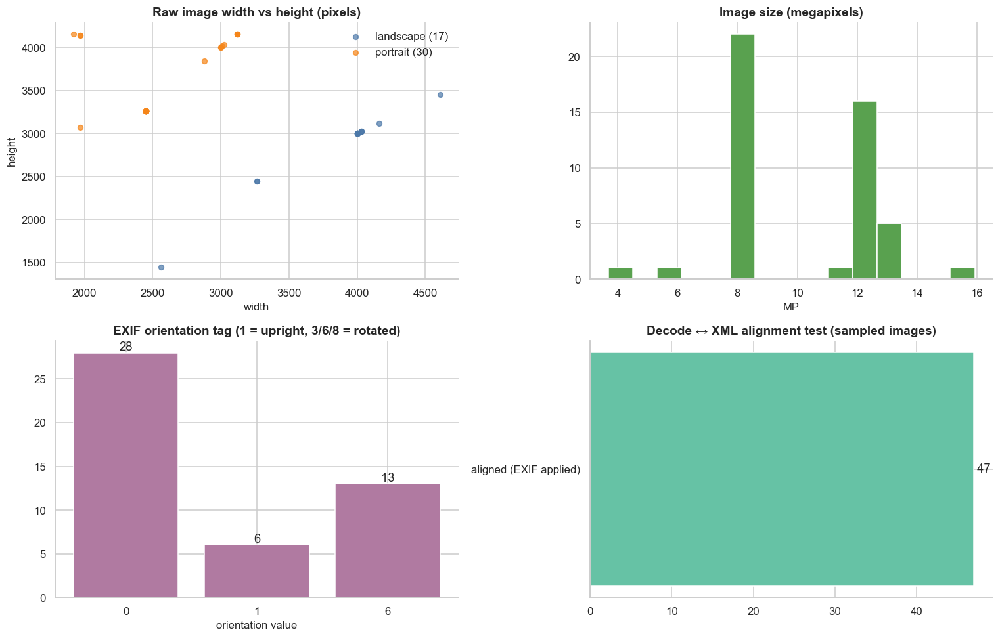

EXIF-rotated images: 87.2% | images needing orientation handling: 0.0% | portrait images: 63.8%


In [22]:
geo_rows = []
for p in plate_images:
    with Image.open(p) as im:
        w, h = im.size
        orient = int(im.getexif().get(274, 1))
    geo_rows.append({"stem": p.stem, "raw_w": w, "raw_h": h, "exif_orientation": orient})
geo = pd.DataFrame(geo_rows)
xml_size = plates_df.groupby("stem")[["img_w", "img_h"]].first().reset_index()
geo = geo.merge(xml_size, on="stem", how="left")
geo["megapixels"] = geo["raw_w"] * geo["raw_h"] / 1e6
geo["layout"] = np.where(geo["raw_w"] >= geo["raw_h"], "landscape", "portrait")
geo["xml_vs_raw"] = np.select([geo["img_w"].isna(),
                               (geo["img_w"] == geo["raw_w"]) & (geo["img_h"] == geo["raw_h"]),
                               (geo["img_w"] == geo["raw_h"]) & (geo["img_h"] == geo["raw_w"])],
                              ["no xml", "match", "swapped (rotation)"], default="other mismatch")

def read_aligned(path, xml_w, xml_h):
    # returns an image whose pixel grid matches the XML coordinate frame, plus how it was obtained
    img = read_bgr(path)
    if img is None:
        return None, "unreadable"
    if xml_w > 0 and (img.shape[1], img.shape[0]) == (int(xml_w), int(xml_h)):
        return img, "aligned (EXIF applied)"
    raw = read_bgr(path, cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if raw is not None and xml_w > 0 and (raw.shape[1], raw.shape[0]) == (int(xml_w), int(xml_h)):
        return raw, "aligned (raw orientation)"
    return img, "size mismatch (rescaled)"

annotated_paths = [p for p in plate_images if p.stem in set(plates_df["stem"])]
PLATE_SAMPLE = sample_paths(annotated_paths, PLATE_SAMPLE_MAX)
xs = xml_size.set_index("stem")
align_status = {}
for p in PLATE_SAMPLE:
    _, align_status[p.stem] = read_aligned(p, xs.loc[p.stem, "img_w"], xs.loc[p.stem, "img_h"])
align_counts = pd.Series(align_status).value_counts()

display(geo["xml_vs_raw"].value_counts().to_frame("images"))
display(geo[["raw_w", "raw_h", "megapixels"]].describe().round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for lay, col in [("landscape", "#4c78a8"), ("portrait", "#f58518")]:
    s = geo[geo["layout"] == lay]
    axes[0, 0].scatter(s["raw_w"], s["raw_h"], s=26, alpha=.7, label=f"{lay} ({len(s)})", color=col)
axes[0, 0].set_title("Raw image width vs height (pixels)"); axes[0, 0].set_xlabel("width"); axes[0, 0].set_ylabel("height"); axes[0, 0].legend()
axes[0, 1].hist(geo["megapixels"], bins=min(25, max(5, len(geo) // 3)), color="#59a14f"); axes[0, 1].set_title("Image size (megapixels)"); axes[0, 1].set_xlabel("MP")
ex = geo["exif_orientation"].value_counts().sort_index()
axes[1, 0].bar(ex.index.astype(str), ex.values, color="#b07aa1")
axes[1, 0].set_title("EXIF orientation tag (1 = upright, 3/6/8 = rotated)"); axes[1, 0].set_xlabel("orientation value")
for i, v in enumerate(ex.values):
    axes[1, 0].text(i, v, str(v), ha="center", va="bottom")
axes[1, 1].barh(align_counts.index, align_counts.values, color=sns.color_palette("Set2", len(align_counts))); axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Decode ↔ XML alignment test (sampled images)")
for y, v in enumerate(align_counts.values):
    axes[1, 1].text(v, y, f" {v}", va="center")
plt.tight_layout(); plt.show()

rotated_pct = float((geo["exif_orientation"] != 1).mean() * 100)
bad_align_pct = float((pd.Series(align_status) != "aligned (EXIF applied)").mean() * 100)   # needs special orientation handling
FINDINGS.update({"exif_rotated_pct": round(rotated_pct, 1), "plate_misaligned_pct": round(bad_align_pct, 1),
                 "plate_portrait_pct": round(float((geo["layout"] == "portrait").mean() * 100), 1),
                 "plate_median_mp": round(float(geo["megapixels"].median()), 2)})
print(f"EXIF-rotated images: {rotated_pct:.1f}% | images needing orientation handling: {bad_align_pct:.1f}% | portrait images: {FINDINGS['plate_portrait_pct']}%")

### 📌 Observation
- **Images are large and heterogeneous:** from 1920×1440 to 4608×4160 px (3.69-15.93 MP, median 8.16 MP), with two main tiers around 8 MP (about 22 images) and 12-13 MP (about 21). **30 of 47 are portrait and 17 landscape** in raw pixels (63.8 % portrait).
- **The EXIF orientation tag is 0 on 28 images, 1 on 6 and 6 (rotate 90°) on 13.** So the printed "EXIF-rotated 87.2 %" **overstates the problem:** tag 0 is not a valid rotation and is effectively upright; only the **13 tag-6 images (27.7 %)** really need rotating.
- **XML size matches raw size for 34 images and is swapped for 13, exactly the 13 tag-6 images.** In the alignment test **all 47 images decode to the XML frame once EXIF is applied**; none needed raw orientation or rescaling.

### 💡 Pipeline / Engineering Decision
- **Always decode with EXIF applied** (OpenCV's default `imread`, or `ImageOps.exif_transpose` with PIL). Ignoring EXIF would swap width and height for 13 images (27.7 %) and misplace every box on them. The same policy holds at serving time.
- **Treat orientation tag 0 as upright,** and count only tags 3, 6 and 8 as rotations when reporting the metric (the current "87.2 %" figure should not be quoted).
- **Add a CI test:** the decoded image size must equal the XML size for every image; it passes today (47 of 47).
- **Letterbox and cap the long side (about 1280 px)** instead of stretching: the sources are 4-16 MP and mix portrait and landscape.

## 🔹 Step 23 — Plate Geometry — Relative Size, Aspect Ratio & Position

### ❓ Why
How much of the image the plate occupies, its aspect ratio (a one-line car plate and a two-line scooter plate are very different shapes) and where it sits in the frame define the detector's job. Reference lines mark the nominal aspect ratios of Indian one-line (≈ 4.2) and two-line (≈ 2) plates.

### 💼 Business Insight
The camera setup determines everything: plates that fill a large fraction of the image are easy to read but come from close-range manual capture, whereas a roadside camera sees plates that are a tiny fraction of the frame. The gap between the two defines whether this dataset's accuracy will transfer to the real deployment.

,rel_area,aspect,bw,bh
count,52.0000,52.0000,52.0000,52.0000
mean,0.0567,2.3554,849.2404,416.5248
std,0.0809,0.8806,639.9164,381.7600
min,0.0001,0.5665,30.5100,22.2800
5%,0.0003,1.3021,71.5600,45.8670
50%,0.0196,2.1411,733.5250,289.0700
95%,0.1928,3.6636,2087.4285,1073.1785
max,0.4263,4.5872,2742.1800,1865.4700


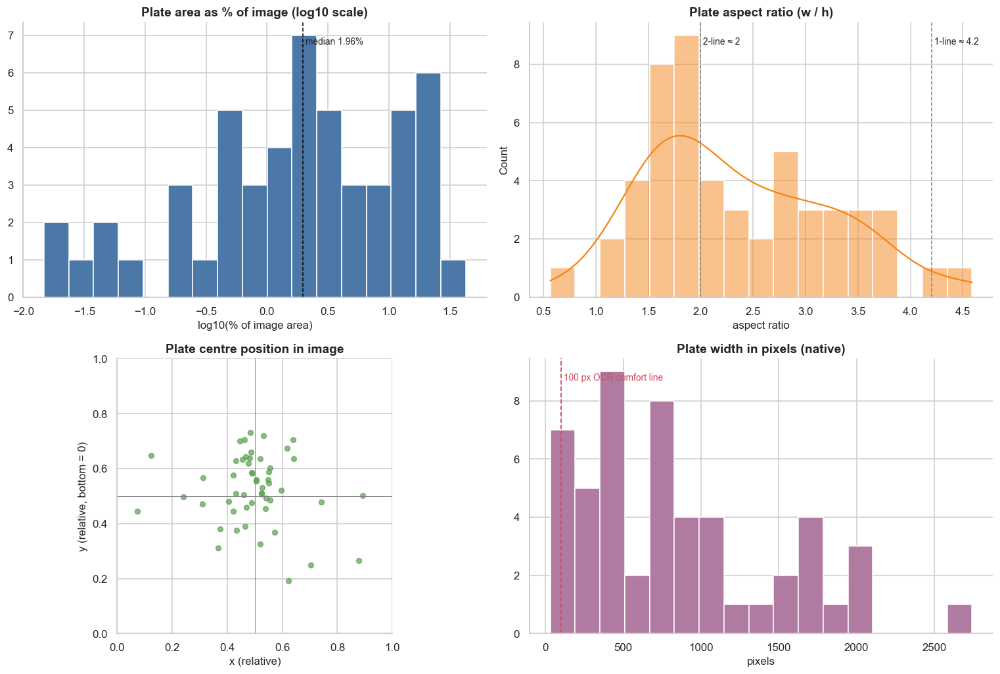

Median plate = 1.96% of image | median aspect = 2.14 | median width = 733.5 px | < 100 px wide: 9.6%


In [23]:
pg = plates_df.dropna(subset=["rel_area", "aspect"])
pct = pg[["rel_area", "aspect", "bw", "bh"]].describe(percentiles=[.05, .5, .95]).round(4)
display(pct)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
axes[0, 0].hist(np.log10(pg["rel_area"] * 100), bins=min(30, max(6, len(pg) // 3)), color="#4c78a8")
axes[0, 0].set_title("Plate area as % of image (log10 scale)"); axes[0, 0].set_xlabel("log10(% of image area)")
med_area = pg["rel_area"].median() * 100
axes[0, 0].axvline(np.log10(med_area), color="black", ls="--", lw=1); axes[0, 0].text(np.log10(med_area), axes[0, 0].get_ylim()[1] * .92, f" median {med_area:.2f}%", fontsize=9)

sns.histplot(pg["aspect"].clip(upper=8), bins=min(30, max(6, len(pg) // 3)), kde=True, color="#f58518", ax=axes[0, 1])
for v, t in [(2.0, "2-line ≈ 2"), (4.2, "1-line ≈ 4.2")]:
    axes[0, 1].axvline(v, color="grey", ls="--", lw=1); axes[0, 1].text(v, axes[0, 1].get_ylim()[1] * .92, f" {t}", fontsize=9)
axes[0, 1].set_title("Plate aspect ratio (w / h)"); axes[0, 1].set_xlabel("aspect ratio")

axes[1, 0].scatter(pg["cx_rel"], 1 - pg["cy_rel"], s=26, alpha=.7, color="#59a14f")
axes[1, 0].set_xlim(0, 1); axes[1, 0].set_ylim(0, 1); axes[1, 0].set_aspect("equal")
axes[1, 0].set_title("Plate centre position in image"); axes[1, 0].set_xlabel("x (relative)"); axes[1, 0].set_ylabel("y (relative, bottom = 0)")
axes[1, 0].axvline(.5, color="grey", lw=.6); axes[1, 0].axhline(.5, color="grey", lw=.6)

axes[1, 1].hist(pg["bw"], bins=min(30, max(6, len(pg) // 3)), color="#b07aa1")
axes[1, 1].axvline(100, color="#d1495b", ls="--", lw=1.2); axes[1, 1].text(100, axes[1, 1].get_ylim()[1] * .92, " 100 px OCR-comfort line", color="#d1495b", fontsize=9)
axes[1, 1].set_title("Plate width in pixels (native)"); axes[1, 1].set_xlabel("pixels")
plt.tight_layout(); plt.show()

FINDINGS.update({"plate_rel_area_median_pct": round(float(med_area), 3), "plate_aspect_median": round(float(pg["aspect"].median()), 2),
                 "plate_width_median_px": round(float(pg["bw"].median()), 1),
                 "plate_narrow_pct": round(float((pg["bw"] < 100).mean() * 100), 1),
                 "plate_two_line_pct": round(float((pg["aspect"] < 3).mean() * 100), 1)})
print(f"Median plate = {med_area:.2f}% of image | median aspect = {FINDINGS['plate_aspect_median']} | median width = {FINDINGS['plate_width_median_px']} px | < 100 px wide: {FINDINGS['plate_narrow_pct']}%")

### 📌 Observation
- **Plate size spans more than three orders of magnitude:** median 1.96 % of the image area, p5 0.03 %, p95 19.3 %, maximum 42.6 %; the log histogram is wide and flat with no single mode. Width is 30.5-2,742 px (median 733.5 px) and **9.6 % of plates (5 boxes) are narrower than 100 px.**
- **Aspect ratio is not one-line-plate shaped:** median 2.14 (p5 1.30, p95 3.66, maximum 4.59). The main mode is at 1.6-1.9 (two-line or squarish plates), with a shoulder at 2.8-3.8, and only two boxes are near the 4.2 one-line reference.
- **Plate centres lie slightly above the image centre,** clustered at about x = 0.4-0.65 and y = 0.45-0.7 (from the bottom), with a few outliers near the left and right edges.

### 💡 Pipeline / Engineering Decision
- **Plate detector input is 1280 px, not 640 px:** after resizing a 3,000-4,000 px image to 1280 the median plate is still about 230-290 px wide, but at 640 it would be about 120 px and the narrowest plates would shrink to a few pixels. Combine with multi-scale augmentation, since plates span 30-2,742 px.
- **OCR must handle both layouts** (two-line and single-line): aspect-preserving resize with padding, never a fixed stretch.
- **No fixed ROI or positional prior,** and random translation/crop augmentation breaks the photographer's centre bias, because deployment plates will not be centred.
- **Very small plates go to a quality-gate branch** (Step 25) instead of straight to OCR.

## 🔹 Step 24 — Plate-Text Analysis — Length, Format Grammar, State Codes & Character Frequency

### ❓ Why
Indian plates follow a grammar: two-letter state/UT code, one or two digits (RTO), up to three series letters, then up to four digits; newer *BH series* plates follow a different pattern. Regex-based validation plus length, state-code and character-frequency charts show how clean and how diverse the ground-truth text is, and which characters the OCR will confuse.

### 💼 Business Insight
Recognition accuracy has to be measured per character *and* per full plate; a single wrong character produces the wrong vehicle record. Knowing the format distribution lets us add cheap, high-value post-processing (grammar validation, state-code correction) that lifts effective accuracy without retraining.

,plate_text,plate_norm,length,format,state,state_ok
27,KL34A465,KL34A465,8,standard,KL,True
28,KL34A465,KL34A465,8,standard,KL,True
29,KL34F,KL34F,5,non-standard / noisy,KL,False
30,KL35F4337,KL35F4337,9,standard,KL,True
31,KL35H5834,KL35H5834,9,standard,KL,True
32,KL03S6894,KL03S6894,9,standard,KL,True
33,UP84AE9889,UP84AE9889,10,standard,UP,True
34,GJ01DY6855,GJ01DY6855,10,standard,GJ,True
35,KL498262,KL498262,8,standard,KL,True
36,WB42AX7446,WB42AX7446,10,standard,WB,True


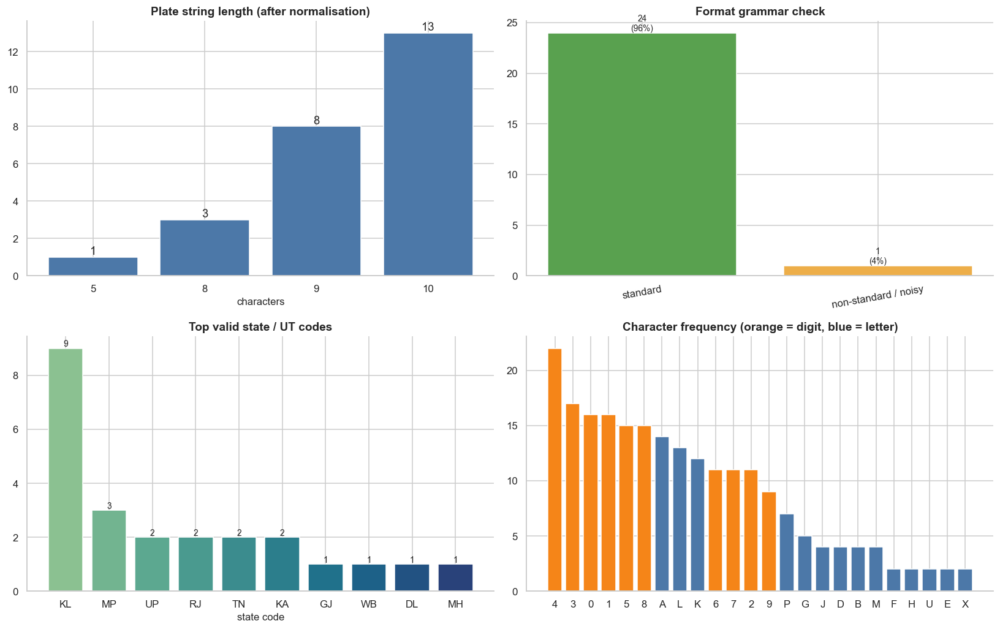

Non-standard strings: 4.0% | confusable characters (0/O, 1/I, 8/B, 5/S, 2/Z): 33.8% | distinct valid states: 10


In [24]:
STATE_CODES = set("AN AP AR AS BR CG CH DD DL DN GA GJ HP HR JH JK KA KL LA LD MH ML MN MP MZ NL OD OR PB PY RJ SK TN TR TS UK UP WB".split())
STD = re.compile(r"^[A-Z]{2}\d{1,2}[A-Z]{0,3}\d{1,4}$")
BH  = re.compile(r"^\d{2}BH\d{4}[A-Z]{1,2}$")

txt = plates_df.dropna(subset=["plate_text"]).copy()
txt["plate_norm"] = txt["plate_text"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
txt = txt[txt["plate_norm"] != ""]

if txt.empty:
    print("⚠️  No plate text found in the annotations — plate-text analysis skipped.")
    FINDINGS.update({"plate_nonstd_pct": None, "plate_confusable_pct": None})
else:
    txt["length"] = txt["plate_norm"].str.len()
    txt["format"] = np.where(txt["plate_norm"].apply(lambda s: bool(BH.match(s))), "BH-series",
                     np.where(txt["plate_norm"].apply(lambda s: bool(STD.match(s))), "standard", "non-standard / noisy"))
    txt["state"] = txt["plate_norm"].str[:2]
    txt["state_ok"] = txt["state"].isin(STATE_CODES) & (txt["format"] == "standard")
    chars = Counter("".join(txt["plate_norm"]))
    CONFUSABLE = set("0O1I8B5S2Z")
    confusable_pct = sum(v for k, v in chars.items() if k in CONFUSABLE) / sum(chars.values()) * 100

    display(txt[["plate_text", "plate_norm", "length", "format", "state", "state_ok"]].head(10))
    fmt_counts = txt["format"].value_counts()
    top_states = txt.loc[txt["state_ok"], "state"].value_counts().head(12)
    char_df = pd.DataFrame(sorted(chars.items(), key=lambda kv: -kv[1])[:24], columns=["char", "count"])

    fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
    lc = txt["length"].value_counts().sort_index()
    axes[0, 0].bar(lc.index.astype(str), lc.values, color="#4c78a8"); axes[0, 0].set_title("Plate string length (after normalisation)"); axes[0, 0].set_xlabel("characters")
    for i, v in enumerate(lc.values):
        axes[0, 0].text(i, v, str(v), ha="center", va="bottom")
    axes[0, 1].bar(fmt_counts.index, fmt_counts.values, color=["#59a14f", "#edae49", "#e15759", "#4c78a8"][:len(fmt_counts)])
    axes[0, 1].set_title("Format grammar check"); axes[0, 1].tick_params(axis="x", labelrotation=10)
    for i, v in enumerate(fmt_counts.values):
        axes[0, 1].text(i, v, f"{v}\n({v/len(txt)*100:.0f}%)", ha="center", va="bottom", fontsize=9)
    if len(top_states):
        axes[1, 0].bar(top_states.index, top_states.values, color=sns.color_palette("crest", len(top_states)))
        for i, v in enumerate(top_states.values):
            axes[1, 0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
    axes[1, 0].set_title("Top valid state / UT codes"); axes[1, 0].set_xlabel("state code")
    axes[1, 1].bar(char_df["char"], char_df["count"], color=["#f58518" if c.isdigit() else "#4c78a8" for c in char_df["char"]])
    axes[1, 1].set_title("Character frequency (orange = digit, blue = letter)")
    plt.tight_layout(); plt.show()

    nonstd = float((txt["format"] == "non-standard / noisy").mean() * 100)
    FINDINGS.update({"plate_nonstd_pct": round(nonstd, 1), "plate_confusable_pct": round(float(confusable_pct), 1),
                     "plate_distinct_states": int(txt.loc[txt["state_ok"], "state"].nunique()), "plate_texts_n": int(len(txt)),
                     "plate_modal_len": int(txt["length"].mode().iloc[0])})
    print(f"Non-standard strings: {nonstd:.1f}% | confusable characters (0/O, 1/I, 8/B, 5/S, 2/Z): {confusable_pct:.1f}% | distinct valid states: {FINDINGS['plate_distinct_states']}")

### 📌 Observation
- **25 transcribed plates:** lengths are 10 characters (13 plates), 9 (8), 8 (3) and 5 (1). **24 of 25 (96 %) match the standard grammar, 0 are BH-series, and 1 (4 %) is non-standard:** `KL34F`, a 5-character string that looks like a truncated or partly visible plate.
- **State coverage is tiny and skewed:** KL has 9 plates (36 % of the strings), MP 3, UP, RJ, TN and KA 2 each, GJ, WB, DL and MH 1 each, i.e. only 10 distinct states.
- **Character frequencies:** digit 4 is the most common character (22), then 3 (17) and 0 and 1 (16 each); the leading letters A, L and K are inflated by the KL prefix. **33.8 % of all characters belong to the confusable set** (0/O, 1/I, 8/B, 5/S, 2/Z).

### 💡 Pipeline / Engineering Decision
- **Grammar-constrained decoding is justified:** 96 % of ground-truth strings already satisfy the plate regex, so OCR output can be validated against it, and position-aware character types (letters in letter slots, digits in digit slots) directly fix the 0/O and 1/I confusions.
- **Do not learn state priors from this set:** KL alone is 36 % of 25 strings. Use the national RTO code list with a uniform prior, and report accuracy by state group.
- **25 strings are too few to train or to measure precisely:** an observed exact-match of 80 % would have a 95 % Wilson interval of about 61-91 %. Generate synthetic plates (tens of thousands) with varied fonts, two-line layouts and the grammar above, and weight the loss on confusable pairs.
- **The one non-standard string goes to the review list** and is excluded from exact-match scoring until checked.

## 🔹 Step 25 — Plate-Crop Quality — Size, Sharpness, Brightness & OCR-Readiness Gate

### ❓ Why
What matters for OCR is the quality of the *crop*, not the full photo. For every annotated plate we measure the crop's pixel size, sharpness (Laplacian variance), brightness and contrast, and define a quality gate from the observed distribution. The scatter of size against sharpness shows whether small plates are also the blurry ones.

### 💼 Business Insight
A plate that is too small or too blurry cannot be read reliably by any model. A quality gate that refuses low-confidence reads and routes them to manual review is what keeps an enforcement system legally defensible — a wrong fine costs far more, in money and trust, than a skipped one.

,crop_w,crop_h,brightness,contrast,sharpness
count,52.0,52.0,52.0,52.0,52.0
mean,849.2,416.4,125.6,54.3,449.4
std,640.0,381.8,36.3,18.7,459.5
min,31.0,23.0,60.9,9.1,7.6
10%,124.9,56.1,76.8,24.6,59.5
50%,734.0,289.5,128.0,56.7,322.2
90%,1706.4,936.3,167.8,78.3,1118.8
max,2742.0,1866.0,204.1,84.5,1994.6


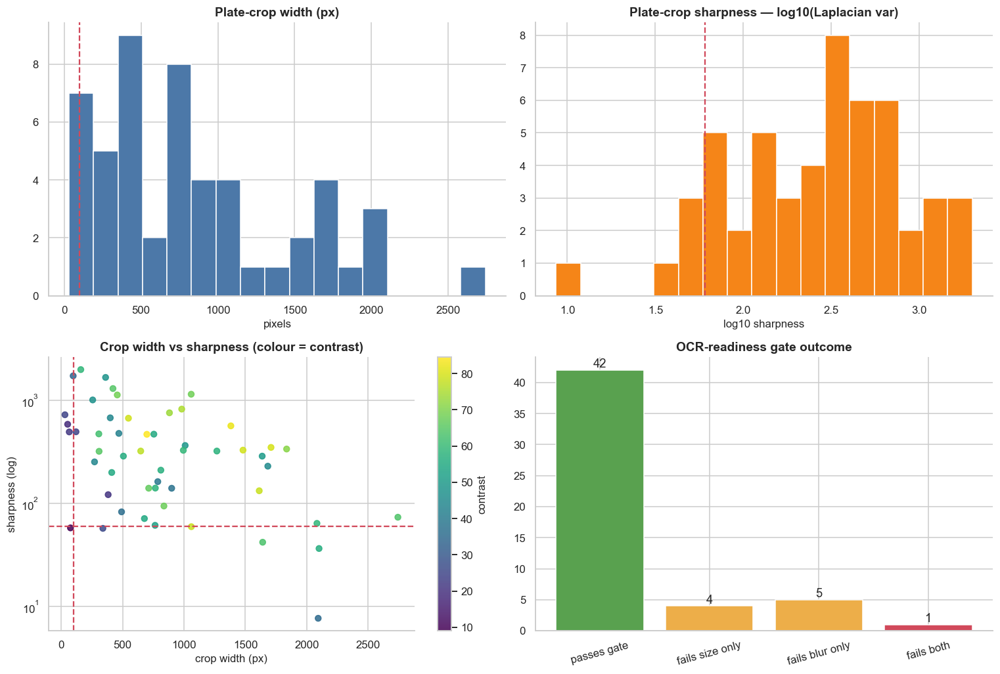

Gate: width ≥ 100px and sharpness ≥ 59.5 → 19.2% of crops rejected | OCR input (h×w) = 48×104


In [25]:
crop_rows, img_rows = [], []
by_stem = {s: g for s, g in plates_df.groupby("stem")}
for p in PLATE_SAMPLE:
    g = by_stem[p.stem]
    img, status = read_aligned(p, g["img_w"].iloc[0], g["img_h"].iloc[0])
    if img is None:
        continue
    gray_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_rows.append({"stem": p.stem, "brightness": float(gray_full.mean()), "contrast": float(gray_full.std()),
                     "sharpness": float(cv2.Laplacian(gray_full, cv2.CV_64F).var()), "status": status})
    sx, sy = img.shape[1] / g["img_w"].iloc[0], img.shape[0] / g["img_h"].iloc[0]
    for r in g.itertuples():
        x1, x2 = int(max(0, r.xmin * sx)), int(min(img.shape[1], r.xmax * sx))
        y1, y2 = int(max(0, r.ymin * sy)), int(min(img.shape[0], r.ymax * sy))
        if x2 - x1 < 4 or y2 - y1 < 4:
            continue
        crop = gray_full[y1:y2, x1:x2]
        crop_rows.append({"stem": p.stem, "crop_w": x2 - x1, "crop_h": y2 - y1, "brightness": float(crop.mean()),
                          "contrast": float(crop.std()), "sharpness": float(cv2.Laplacian(crop, cv2.CV_64F).var())})

plate_img_quality = pd.DataFrame(img_rows)
crops = pd.DataFrame(crop_rows)
crops["log_sharpness"] = np.log10(crops["sharpness"] + 1)
display(crops[["crop_w", "crop_h", "brightness", "contrast", "sharpness"]].describe(percentiles=[.1, .5, .9]).round(1))

MIN_W = 100
BLUR_THR = float(crops["sharpness"].quantile(0.10))
crops["fails_size"], crops["fails_blur"] = crops["crop_w"] < MIN_W, crops["sharpness"] < BLUR_THR
crops["rejected"] = crops["fails_size"] | crops["fails_blur"]
med_aspect = float(plates_df["aspect"].median())
ocr_h = 48; ocr_w = int(round(ocr_h * med_aspect / 8) * 8)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
axes[0, 0].hist(crops["crop_w"], bins=min(30, max(6, len(crops) // 3)), color="#4c78a8")
axes[0, 0].axvline(MIN_W, color="#d1495b", ls="--"); axes[0, 0].set_title("Plate-crop width (px)"); axes[0, 0].set_xlabel("pixels")
axes[0, 1].hist(crops["log_sharpness"], bins=min(30, max(6, len(crops) // 3)), color="#f58518")
axes[0, 1].axvline(np.log10(BLUR_THR + 1), color="#d1495b", ls="--"); axes[0, 1].set_title("Plate-crop sharpness — log10(Laplacian var)"); axes[0, 1].set_xlabel("log10 sharpness")
sc = axes[1, 0].scatter(crops["crop_w"], crops["sharpness"], c=crops["contrast"], cmap="viridis", s=34, alpha=.85)
axes[1, 0].set_yscale("log"); axes[1, 0].axvline(MIN_W, color="#d1495b", ls="--"); axes[1, 0].axhline(BLUR_THR, color="#d1495b", ls="--")
axes[1, 0].set_title("Crop width vs sharpness (colour = contrast)"); axes[1, 0].set_xlabel("crop width (px)"); axes[1, 0].set_ylabel("sharpness (log)")
plt.colorbar(sc, ax=axes[1, 0], label="contrast")
gate = pd.Series({"passes gate": int((~crops["rejected"]).sum()), "fails size only": int((crops["fails_size"] & ~crops["fails_blur"]).sum()),
                  "fails blur only": int((~crops["fails_size"] & crops["fails_blur"]).sum()), "fails both": int((crops["fails_size"] & crops["fails_blur"]).sum())})
axes[1, 1].bar(gate.index, gate.values, color=["#59a14f", "#edae49", "#edae49", "#d1495b"]); axes[1, 1].tick_params(axis="x", labelrotation=15)
axes[1, 1].set_title("OCR-readiness gate outcome")
for i, v in enumerate(gate.values):
    axes[1, 1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

FINDINGS.update({"min_crop_w": MIN_W, "blur_threshold": round(BLUR_THR, 1), "crop_reject_pct": round(float(crops["rejected"].mean() * 100), 1),
                 "ocr_input_hw": (ocr_h, ocr_w), "plate_crop_median_w": round(float(crops["crop_w"].median()), 1),
                 "plate_median_sharpness": round(float(plate_img_quality["sharpness"].median()), 1),
                 "plate_median_brightness": round(float(plate_img_quality["brightness"].median()), 1)})
print(f"Gate: width ≥ {MIN_W}px and sharpness ≥ {BLUR_THR:.1f} → {FINDINGS['crop_reject_pct']}% of crops rejected | OCR input (h×w) = {ocr_h}×{ocr_w}")

### 📌 Observation
- **52 crops:** width median 734 px (p10 124.9, minimum 31, maximum 2,742), height median 289.5 px, sharpness median 322 (p10 59.5, minimum 7.6) and contrast median 56.7.
- **The gate (width ≥ 100 px and sharpness ≥ 59.5) passes 42 crops, fails 4 on size only, 5 on blur only and 1 on both: 10 of 52 (19.2 %) are rejected.**
- In the scatter, the very narrow crops (under about 100 px) are low-contrast (dark purple) but still score high on the Laplacian measure, while several of the **blur-failing crops are very wide (1,600-2,100 px)** with sharpness of 8-65. So the sharpness metric is **resolution-dependent:** it falls as crops get larger, and the rule does not behave like "small means blurry".
- The OCR input height × width derived from the median aspect is 48×104.

### 💡 Pipeline / Engineering Decision
- **Make the blur gate scale-invariant:** compute sharpness after resizing every crop to a fixed height (for example 64 px). Otherwise large soft crops are rejected while tiny noisy crops pass.
- **Add a contrast gate:** the narrowest crops have contrast of roughly 10-35 and are the likeliest to be unreadable.
- **OCR input should not be a fixed 48×104:** that width suits the median aspect (2.14) but squeezes single-line plates (aspect up to 4.6). Use a fixed height (for example 64 px) with two width buckets or a variable-width model, and pad rather than stretch.
- **Treat 59.5 as provisional:** it is the 10th percentile of only 52 crops, and the gate is recalibrated on real deployment footage. Rejected plates go to super-resolution and then to a manual-review queue, never straight to an automatic decision.

## 🔹 Step 26 — Visual Audit — Plate Boxes, Transcriptions & Crops

### ❓ Why
A final visual check confirms that boxes, transcriptions and image orientation agree, and shows the variety the OCR must handle (vehicle types, one- and two-line plates, dirt, angle, lighting). The top rows show full images with the annotated box and text; the bottom rows show the extracted crops exactly as OCR would receive them.

### 💼 Business Insight
This is the single most convincing artefact for a stakeholder or reviewer: it shows the real operating conditions of the data in one figure. It is also the quickest way to detect systematic annotation problems (offset boxes, wrong transcriptions) that no statistic reveals.

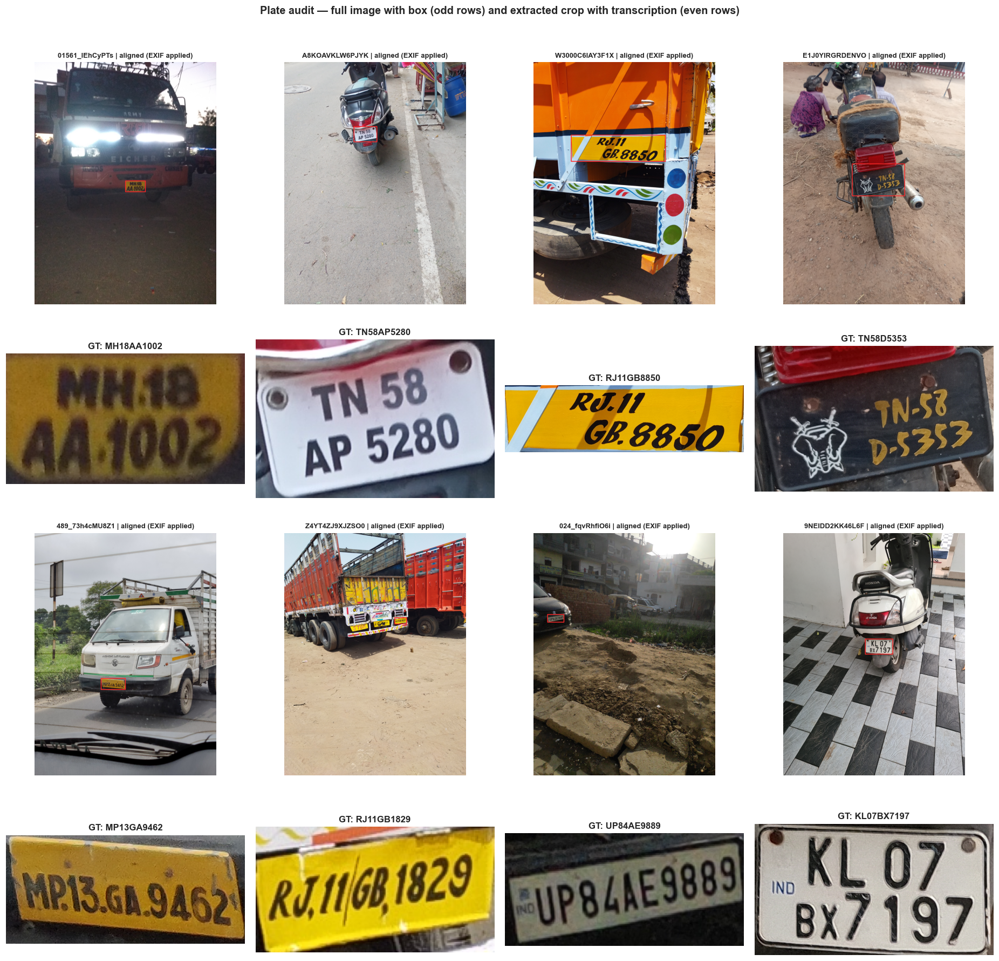

In [26]:
rng = np.random.default_rng(SEED)
with_text = [p for p in PLATE_SAMPLE if by_stem[p.stem]["plate_text"].notna().any()]
pool = with_text if len(with_text) >= 8 else PLATE_SAMPLE
chosen = [pool[i] for i in rng.choice(len(pool), size=min(8, len(pool)), replace=False)]

n_cols = 4
n_img_rows = int(np.ceil(len(chosen) / n_cols))
fig, axes = plt.subplots(n_img_rows * 2, n_cols, figsize=(17, 4.3 * n_img_rows * 2))
axes = np.atleast_2d(axes)
for a in axes.ravel():
    a.axis("off")

for i, p in enumerate(chosen):
    g = by_stem[p.stem]
    img, status = read_aligned(p, g["img_w"].iloc[0], g["img_h"].iloc[0])
    if img is None:
        continue
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    sx, sy = rgb.shape[1] / g["img_w"].iloc[0], rgb.shape[0] / g["img_h"].iloc[0]
    r0 = g.iloc[0]
    x1, y1, x2, y2 = int(r0.xmin * sx), int(r0.ymin * sy), int(r0.xmax * sx), int(r0.ymax * sy)
    vis = rgb.copy()
    cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 40, 40), max(3, rgb.shape[1] // 250))
    row, col = (i // n_cols) * 2, i % n_cols
    axes[row, col].imshow(vis); axes[row, col].set_title(f"{p.stem[-14:]} | {status}", fontsize=8.5)
    crop = rgb[max(0, y1):y2, max(0, x1):x2]
    if crop.size:
        axes[row + 1, col].imshow(crop)
        axes[row + 1, col].set_title(f"GT: {r0.plate_text if r0.plate_text else '— no text —'}", fontsize=11, fontweight="bold")
plt.suptitle("Plate audit — full image with box (odd rows) and extracted crop with transcription (even rows)", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

### 📌 Observation
- **The eight samples cover trucks, a tempo van, scooters, motorcycles and a car at a distance,** in very different surroundings. Plate colours vary: yellow commercial plates (MH18AA1002, RJ11GB8850, RJ11GB1829, MP13GA9462), white private plates (TN58AP5280, UP84AE9889, KL07BX7197) and a black plate with yellow text and a decorative logo (TN58D5353).
- **Both layouts occur:** two-line plates (MH18/AA1002, TN58/AP5280, KL07/BX7197, RJ11/GB8850) and single-line plates (UP84AE9889, MP13GA9462).
- **Hard cases are visible:** italic and stencil fonts, dot and bar separators, an "IND" strip, dirt, a slanted plate (RJ11GB1829), a truck plate under strong headlight glare at dusk (first image, low-resolution crop) and a tiny plate on a distant car (row 3, centre).
- **Every caption shows "aligned (EXIF applied)":** the boxes sit tightly on the plates, and the ground-truth text matches what is visible in all eight crops.

### 💡 Pipeline / Engineering Decision
- **Augmentation recipe for the plate stage:** perspective/affine warps (about ±15°), motion blur, exposure/gamma changes for glare, and colour jitter that keeps plate background colours intact. Do not shift hue much, because yellow (commercial) versus white (private) is meaningful and a hue shift could turn one into the other.
- **Synthetic data must include italic and stencil fonts, separators and the "IND" strip,** because the real crops contain them.
- **OCR labels are alphanumeric only (`MH18AA1002`):** the separators and line breaks seen in the images do not appear in the ground truth, so the model must learn to ignore them (a CTC-style blank handles this).
- **A rectification step (perspective correction) before OCR is a worthwhile early experiment** for slanted plates, and this grid is regenerated for each new data drop as a visual QA gate.

# 🅓 Part D — Synthesis: Domain Gap & Pipeline Decisions

## 🔹 Step 27 — Cross-Dataset Domain Gap — CCTV Vehicles vs Phone-Captured Plates

### ❓ Why
The two datasets describe the same road but through completely different cameras. Overlaying their object-scale, brightness, sharpness and resolution distributions quantifies the *domain gap* and answers the key architecture question: can one model serve both tasks, or are two stages required?

### 💼 Business Insight
A system trained on close-up plate photos will see plates that are tiny and blurry on a roadside camera, and one trained only on CCTV vehicles has no plate ground truth at all. Understanding the gap prevents the most common capstone failure — a model that looks great on its own test set and collapses on the deployment camera.

,median object area (% of image),median brightness,median sharpness (Laplacian var),median megapixels
"UA-DETRAC (vehicles, CCTV)",0.763,115.152,392.378,0.518
"Indian plates (plate box, phone)",1.961,118.474,160.688,8.155


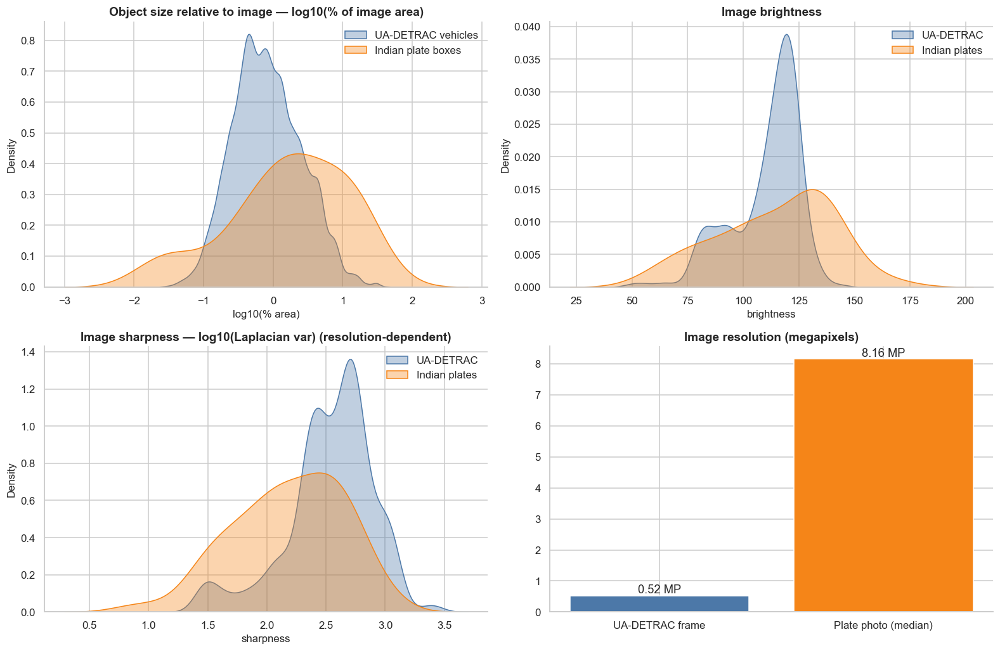

Median plate occupies 3× more of its image than a median DETRAC vehicle does


In [27]:
detrac_rel = (det["w"] * det["h"]).sample(min(len(det), 100_000), random_state=SEED) * 100
plate_rel  = plates_df["rel_area"].dropna() * 100
detrac_mp  = IMG_W * IMG_H / 1e6
plate_mp   = geo["megapixels"]

gap_table = pd.DataFrame({
    "median object area (% of image)": [detrac_rel.median(), plate_rel.median()],
    "median brightness":               [quality_df["brightness"].median(), plate_img_quality["brightness"].median()],
    "median sharpness (Laplacian var)":[quality_df["sharpness"].median(), plate_img_quality["sharpness"].median()],
    "median megapixels":               [detrac_mp, plate_mp.median()],
}, index=["UA-DETRAC (vehicles, CCTV)", "Indian plates (plate box, phone)"]).round(3)
display(gap_table)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.5))
sns.kdeplot(np.log10(detrac_rel), ax=axes[0, 0], fill=True, alpha=.35, label="UA-DETRAC vehicles", color="#4c78a8", warn_singular=False)
sns.kdeplot(np.log10(plate_rel), ax=axes[0, 0], fill=True, alpha=.35, label="Indian plate boxes", color="#f58518", warn_singular=False)
axes[0, 0].set_title("Object size relative to image — log10(% of image area)"); axes[0, 0].set_xlabel("log10(% area)"); axes[0, 0].legend()
sns.kdeplot(quality_df["brightness"], ax=axes[0, 1], fill=True, alpha=.35, label="UA-DETRAC", color="#4c78a8")
sns.kdeplot(plate_img_quality["brightness"], ax=axes[0, 1], fill=True, alpha=.35, label="Indian plates", color="#f58518")
axes[0, 1].set_title("Image brightness"); axes[0, 1].legend()
sns.kdeplot(np.log10(quality_df["sharpness"] + 1), ax=axes[1, 0], fill=True, alpha=.35, label="UA-DETRAC", color="#4c78a8")
sns.kdeplot(np.log10(plate_img_quality["sharpness"] + 1), ax=axes[1, 0], fill=True, alpha=.35, label="Indian plates", color="#f58518")
axes[1, 0].set_title("Image sharpness — log10(Laplacian var) (resolution-dependent)"); axes[1, 0].legend()
axes[1, 1].bar(["UA-DETRAC frame", "Plate photo (median)"], [detrac_mp, plate_mp.median()], color=["#4c78a8", "#f58518"])
axes[1, 1].set_title("Image resolution (megapixels)")
for i, v in enumerate([detrac_mp, plate_mp.median()]):
    axes[1, 1].text(i, v, f"{v:.2f} MP", ha="center", va="bottom")
plt.tight_layout(); plt.show()

gap_ratio = float(plate_rel.median() / max(detrac_rel.median(), 1e-9))
FINDINGS["domain_gap_ratio"] = round(gap_ratio, 1)
FINDINGS["detrac_median_rel_pct"] = round(float(detrac_rel.median()), 4)
print(f"Median plate occupies {gap_ratio:,.0f}× more of its image than a median DETRAC vehicle does")

### 📌 Observation
- **Medians:** object area 0.763 % of the image for DETRAC vehicles against 1.961 % for plate boxes (only about 2.6× apart, though the printed text rounds it to "3×"); brightness 115.2 against 118.5; Laplacian sharpness 392 against 161; resolution 0.52 MP against 8.16 MP (about 16×).
- **The relative-size distributions overlap heavily:** DETRAC is a narrow peak, plates a much broader curve from about -2 to +1.5 in log10(% area). Brightness is a sharp peak at about 120 for DETRAC and a broad 50-180 spread for plates. Plate sharpness is lower and wider, partly because the Laplacian measure depends on resolution.
- **Relative size hides the real gap, which is in absolute pixels.** The median DETRAC vehicle is only about 63 px across (class id 1: 74.6 px wide), while the median plate crop is 734 px wide. If a plate is roughly 25-30 % of a car's width (an assumption), a plate on a typical DETRAC car is only about **19-22 px wide**, and about 45-55 px even for a car at the 95th size percentile.

### 💡 Pipeline / Engineering Decision
- **Two stages are still required, but the second stage needs a different camera:** plate reading on 960×540 CCTV frames is not feasible, because even large vehicles give plates well under the 100 px comfort line from Step 25. Deploy Stage 1 (vehicle detection and counting) on wide CCTV, and Stage 2 (plate detection and OCR) on a dedicated high-resolution ANPR camera triggered by Stage 1.
- **Measure the feasibility threshold instead of guessing it:** downscale the 25 transcribed plate crops to widths of 20, 40, 80, 120 and 160 px, run OCR on each, and plot exact-match against width. That curve sets the minimum camera specification.
- **Train the OCR on synthetically degraded plates** (down-scaling, blur, JPEG) so that it matches what Stage 1 crops actually look like.
- **The risk register's "Moderate" domain-gap score is based on the relative-area ratio and understates this gap;** treat it as High until the width curve above is measured.

## 🔹 Step 28 — Risk Register & Data-Driven Pipeline Configuration

### ❓ Why
All evidence collected in the notebook (`FINDINGS`) is converted into a severity-scored risk register and a single machine-readable pipeline configuration. Scoring rules are explicit thresholds, so the output is traceable to the data rather than to opinion; the config is printed (not saved) for transfer into the training project.

### 💼 Business Insight
This is the executive hand-off: it tells stakeholders which risks threaten the project, how severe they are, what has been done about each, and what the model-building phase will do differently because of the EDA. It converts analysis into a plan and into a defensible go / no-go discussion.

,risk,level,evidence,mitigation
0,Class imbalance (vehicle types),Critical,max/min = 51.0x; majority 'bus' = 82.6%,"Class-weighted loss, repeat-factor sampling, p..."
1,Tiny plate dataset,Critical,47 matched image–annotation pairs,"Transfer learning, strong augmentation, k-fold..."
2,Frame redundancy (low effective sample size),High,lag-1 ACF = 0.983,Frame stride = 30 for training
3,OCR-unreadable crops,Moderate,19.2% of crops fail size/blur gate,Quality gate + super-resolution + manual revie...
4,Domain gap (CCTV vs phone),Moderate,plate occupies 2.6× more of its image than a D...,"Two-stage pipeline, crop-scale synthetic train..."
5,Small / distant vehicles,Low,9.76% of boxes < 32² px at native resolution,"imgsz=640, small-object head / tiled inference..."
6,Train/val temporal leakage,Low,0 sequences shared between splits,Grouped split by sequence; per-sequence metrics
7,Occlusion / crowding,Low,0.32% of boxes overlap another by IoU > 0.5,"NMS IoU = 0.55, crowded-scene slice"
8,Lighting extremes (night / glare),Low,1.4% of sampled frames dark or over-bright,"Photometric augmentation, condition-sliced eva..."
9,Noisy / non-standard plate text,Low,4.0% of strings fail grammar check,"Grammar-constrained decoding, review queue"


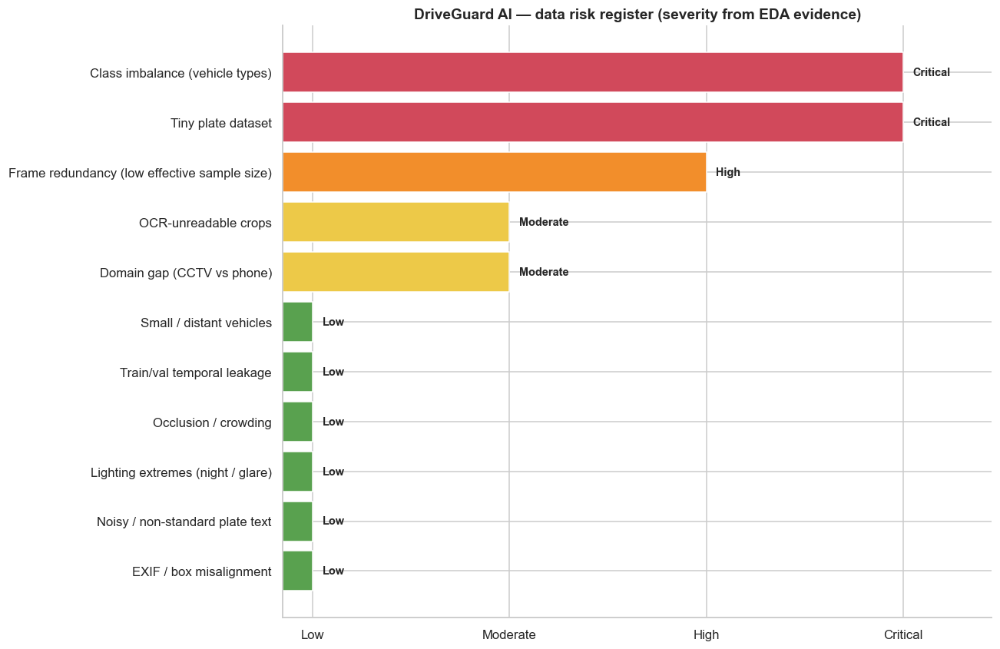

{
  "vehicle_detector": {
    "classes": {
      "0": "car",
      "1": "bus",
      "2": "van",
      "3": "others"
    },
    "imgsz": 640,
    "max_det": 100,
    "nms_iou": 0.55,
    "class_weights": {
      "bus": 0.055,
      "others": 0.547,
      "van": 0.604,
      "car": 2.795
    },
    "split_strategy": "group_by_sequence",
    "train_frame_stride": 30,
    "roi_y_range": [
      0.024,
      0.949
    ],
    "anchors_native_px": [
      [
        36.1,
        28.2
      ],
      [
        59.8,
        42.7
      ],
      [
        89.6,
        46.6
      ],
      [
        87.8,
        88.9
      ],
      [
        125.0,
        64.0
      ],
      [
        164.8,
        85.2
      ],
      [
        138.2,
        139.4
      ],
      [
        212.0,
        113.4
      ],
      [
        283.3,
        122.9
      ],
      [
        200.8,
        259.7
      ],
      [
        387.6,
        198.9
      ],
      [
        597.3,
        233.5
      ]
    ],
    

In [28]:
def g(key, default=None):
    return FINDINGS.get(key, default)

risk_rows = []
def add_risk(name, score, evidence, mitigation):
    risk_rows.append({"risk": name, "severity": int(score), "evidence": evidence, "mitigation": mitigation})

if g("imbalance_ratio") is not None:
    r = g("imbalance_ratio")
    add_risk("Class imbalance (vehicle types)", 3 if r >= 50 else 2 if r >= 10 else 1 if r >= 3 else 0,
             f"max/min = {r}x; majority '{g('majority_class')}' = {g('majority_pct')}%", "Class-weighted loss, repeat-factor sampling, per-class evaluation")
if g("small_share_native") is not None:
    s = g("small_share_native")
    add_risk("Small / distant vehicles", 3 if s >= 50 else 2 if s >= 25 else 1 if s >= 10 else 0,
             f"{s}% of boxes < 32² px at native resolution", f"imgsz={g('rec_imgsz')}, small-object head / tiled inference, AP-small tracking")
lk = g("sequence_overlap")
add_risk("Train/val temporal leakage", 1 if lk is None else 3 if lk > 0 else 0,
         "sequence ids not parseable" if lk is None else f"{lk} sequences shared between splits", "Grouped split by sequence; per-sequence metrics")
if g("acf_lag1") is not None:
    a = g("acf_lag1")
    add_risk("Frame redundancy (low effective sample size)", 2 if a >= 0.9 else 1 if a >= 0.6 else 0,
             f"lag-1 ACF = {a}", f"Frame stride = {g('frame_stride')} for training")
if g("overlap_gt05_pct") is not None:
    o = g("overlap_gt05_pct")
    add_risk("Occlusion / crowding", 2 if o >= 10 else 1 if o >= 3 else 0, f"{o}% of boxes overlap another by IoU > 0.5", f"NMS IoU = {g('nms_iou')}, crowded-scene slice")
if g("dark_pct") is not None:
    d = g("dark_pct") + g("bright_pct")
    add_risk("Lighting extremes (night / glare)", 2 if d >= 20 else 1 if d >= 5 else 0, f"{d:.1f}% of sampled frames dark or over-bright", "Photometric augmentation, condition-sliced evaluation")
n_pl = g("n_plate_pairs", 0)
add_risk("Tiny plate dataset", 3 if n_pl < 200 else 2 if n_pl < 1000 else 0, f"{n_pl} matched image–annotation pairs", "Transfer learning, strong augmentation, k-fold CV, collect more data")
if g("plate_nonstd_pct") is not None:
    n_ = g("plate_nonstd_pct")
    add_risk("Noisy / non-standard plate text", 2 if n_ >= 30 else 1 if n_ >= 10 else 0, f"{n_}% of strings fail grammar check", "Grammar-constrained decoding, review queue")
if g("plate_misaligned_pct") is not None:
    m = g("plate_misaligned_pct")
    add_risk("EXIF / box misalignment", 3 if m >= 10 else 2 if m > 0 else 0, f"{m}% of sampled images need special orientation handling", "Single orientation policy + CI validation")
if g("crop_reject_pct") is not None:
    c = g("crop_reject_pct")
    add_risk("OCR-unreadable crops", 2 if c >= 30 else 1 if c >= 10 else 0, f"{c}% of crops fail size/blur gate", "Quality gate + super-resolution + manual review queue")
if g("domain_gap_ratio") is not None:
    dg = g("domain_gap_ratio")
    add_risk("Domain gap (CCTV vs phone)", 3 if dg >= 20 else 2 if dg >= 5 else 1, f"plate occupies {dg}× more of its image than a DETRAC vehicle", "Two-stage pipeline, crop-scale synthetic training data, deployment-camera test set")

risk_df = pd.DataFrame(risk_rows).sort_values("severity", ascending=False).reset_index(drop=True)
LEVELS = {0: "Low", 1: "Moderate", 2: "High", 3: "Critical"}
risk_df["level"] = risk_df["severity"].map(LEVELS)
display(risk_df[["risk", "level", "evidence", "mitigation"]])

fig, ax = plt.subplots(figsize=(12, 0.55 * len(risk_df) + 1.8))
colors = risk_df["severity"].map({0: "#59a14f", 1: "#edc948", 2: "#f28e2b", 3: "#d1495b"})
ax.barh(risk_df["risk"], risk_df["severity"] + 0.15, color=colors); ax.invert_yaxis()
ax.set_xlim(0, 3.6); ax.set_xticks([0.15, 1.15, 2.15, 3.15]); ax.set_xticklabels(["Low", "Moderate", "High", "Critical"])
ax.set_title("DriveGuard AI — data risk register (severity from EDA evidence)")
for y, (lvl, ev) in enumerate(zip(risk_df["level"], risk_df["evidence"])):
    ax.text(risk_df["severity"].iloc[y] + 0.2, y, f"{lvl}", va="center", fontsize=9.5, fontweight="bold")
plt.tight_layout(); plt.show()

PIPELINE_CONFIG = {
    "vehicle_detector": {
        "classes": CLASS_NAMES, "imgsz": g("rec_imgsz"), "max_det": g("max_det"), "nms_iou": g("nms_iou"),
        "class_weights": g("class_weights"), "split_strategy": "group_by_sequence", "train_frame_stride": g("frame_stride"),
        "roi_y_range": [g("roi_y_low"), g("roi_y_high")], "anchors_native_px": g("anchors_native"),
        "augment": {"hflip": True, "vflip": False, "mosaic": True, "scale_jitter": True,
                    "brightness_p5_p95": g("brightness_range"), "blur": True},
    },
    "plate_stage": {
        "input": "vehicle crops from stage 1", "orientation_policy": "verify decoded size vs XML; EXIF-normalise at serving",
        "split_strategy": "group_by_plate_string + k-fold", "min_crop_width_px": g("min_crop_w"), "blur_threshold": g("blur_threshold"),
        "ocr_input_hw": g("ocr_input_hw"), "plate_regex": r"^[A-Z]{2}\d{1,2}[A-Z]{0,3}\d{1,4}$ | ^\d{2}BH\d{4}[A-Z]{1,2}$",
        "preprocess": ["CLAHE", "aspect-preserving resize + pad", "perspective rectification"],
    },
    "validation": ["per-class AP", "AP-small", "crowded-scene slice", "per-sequence aggregation",
                   "plate exact-match + per-char accuracy", "end-to-end test on deployment-camera set"],
}
print(json.dumps(PIPELINE_CONFIG, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

### 📌 Observation
- **Risk register:** Critical for class imbalance (51×) and the tiny plate dataset (47 pairs); High for frame redundancy (lag-1 ACF 0.983); Moderate for OCR-unreadable crops (19.2 %) and the domain gap (2.6× in relative area); Low for small objects (9.76 %), temporal leakage (0 shared sequences), occlusion (0.32 % of boxes above IoU 0.5), lighting extremes (1.4 %), non-standard plate text (4.0 % of 25) and EXIF misalignment (0 %). The chart shows 2 red, 1 orange, 2 yellow and 6 green bars.
- **The register does not score four problems found in this notebook:** the wrong class names (Steps 4 and 14), the train/val distribution shift (JS 0.1172, up to 5.0 pp, 7.14 against 11.99 objects per image), unlabeled far-field vehicles (Step 14) and the absolute-pixel plate gap (Step 27).
- **The printed config** contains `imgsz` 640, `max_det` 100, `nms_iou` 0.55, 12 anchors, frame stride 30, brightness band 80.5-127.5, and for plates a 100 px width gate, blur threshold 59.5 and OCR input 48×104. Its class weights are keyed by the fallback names and therefore wrong until the class map is fixed.

### 💡 Pipeline / Engineering Decision
- **Decision: GO for vehicle detection, with conditions; NO-GO for plate recognition on DETRAC-class cameras.** Vehicle detection starts now on UA-DETRAC; plate recognition proceeds as a transfer-learning proof of concept and is not promoted without a deployment-camera test set.
- **Config corrections to apply before training:**
  - fix `CLASS_NAMES` and regenerate the class weights;
  - drop `roi_y_range` (it saves no compute);
  - treat `train_frame_stride` 30 as a floor with random offsets;
  - treat the anchors as informational and use an anchor-free head;
  - set the plate detector input to 1280 px;
  - make the blur gate scale-invariant and replace the fixed 48×104 OCR input with aspect buckets.
- **Add four rows to the risk register:** wrong class names (Critical), train/val shift (High), unlabeled far-field vehicles (High) and plate pixel gap (High).
- **Experiment order:** (1) anchor-free YOLO at 640 with square-root class weights, evaluated per class, per sequence and on the crowded slice; (2) ignore-region handling; (3) 5-fold sequence-grouped cross-validation; (4) plate detector at 1280 fine-tuned with cross-validation on the 47 images; (5) synthetic-data OCR plus the OCR-accuracy-versus-width curve.

---

## ✅ EDA Complete — Hand-off Summary

| Area | Key outcome (from the executed run) |
|---|---|
| **Data integrity** | 1,274,055 boxes, 0 defects; 1,879 DETRAC images have no label file (to be inspected); 47/47 plate image–XML pairs matched |
| **Class balance** | One class holds 82.6 % of boxes, imbalance 51×; **class names are wrong (fallback map) and must be fixed** |
| **Split quality** | No sequence leakage (60 train / 40 val), but val is a shifted benchmark: JS 0.1172, 11.99 vs 7.14 objects per image |
| **Vehicle detector settings** | Input 640 px, `max_det` 100, NMS IoU 0.55, anchor-free head, scale jitter, mosaic, photometric ranges from the measured brightness band |
| **Label coverage** | Visible far-field/parked vehicles carry no box (ignored regions): needs loss masking and evaluation masking |
| **Plate data** | 47 images, 52 boxes, 25 transcribed strings; EXIF must be applied (13 of 47 images are rotated) |
| **Plate stage settings** | Detector input 1280 px, grammar-constrained OCR, scale-invariant quality gate, synthetic training data |
| **Architecture** | Two stages confirmed, but plate reading needs a dedicated high-resolution camera: a plate on a typical DETRAC car is only about 20 px wide |

> **Next phase:** fix the class map → ignore-region handling → grouped cross-validation → baseline YOLO → plate detector + OCR → OCR-versus-width feasibility curve → end-to-end evaluation on real deployment footage.